# COMP5048 Assignment 2: Air Quality Sensor Data Analysis

**Group 5** · Tutor: Wanxin (Wilma) Liu

This notebook contains the data processing, the interactive visual analytic tool and the evidence for Tasks 1 to 4. Each section names its owner.

## Team

| Member | Name | SID | Task | Other contributions |
|---|---|---|---|---|
| A | Wang Yuyao | 530075864 | Task 3: Critical moment and what-if | Regression models, notebook integration |
| B | Lian Fengyu | 560843024 | Task 1: Similarity | Data quality checks, figure registry |
| C | Nguyen Huu Hoang Duc | 560825787 | Task 2: Trend analysis | Literature survey, repository management |
| D | Tang Yaqing | 540846788 | Task 4: Evaluation | Data description, project coordination, report assembly |

## Analysis constraints

- All tasks use the same nine numeric attributes plus DateTime (defined in Section 0).
- Values coded `-200` are treated as missing and are never imputed.
- No clustering algorithm is used; groups (G1 to G4) are found from visual evidence only.

## How to run

1. Run the **first code cell**. It extracts the bundled data, helper code and Task 3 dashboard, and prints a local link to the dashboard.
2. Choose **Run All**. If a package is missing, run `%pip install -r requirements.txt`, restart the kernel and run again.
3. Keep the kernel running while using the local dashboard link printed by the first code cell. That cell also saves an offline copy, [Task3_G1_Reverified.html](Task3_G1_Reverified.html), next to this notebook; open it in Chrome or Edge.

## Contents

0. Setup and data processing
1. Task 1: Similarity analysis
2. Task 2: Trend analysis
3. Task 3: Critical moment and what-if analysis
4. Task 4: Evaluation
5. Submission checks


---
# 0. Setup and data processing
**Owner: B (Lian Fengyu)** for data processing and quality checks · **A (Wang Yuyao)** for resource bundling and the Task 3 dashboard

The data processing and data-quality code is kept in reusable modules (`data_processing.py`, `data_quality.py`, `views_common.py`) and run from here, so every section uses the same cleaned dataset. Run the code cell below first: it extracts the bundled files and prints a local link to the Task 3 dashboard.

In [ ]:
# Self-contained project resources. This cell needs only Python's standard library and IPython.
# Run it first to extract the data/code and activate the clickable dashboard link.
import base64, hashlib, io, os, sys, zipfile
from pathlib import Path

_RESOURCE_DATA = "..."
_RESOURCE_SHA256 = "ba1a23559a3b2e9635a7e8bdab8cf3d6f284935a6ca88672c81ee96404528ea6"
_archive_bytes = base64.b64decode(_RESOURCE_DATA)
if hashlib.sha256(_archive_bytes).hexdigest() != _RESOURCE_SHA256:
    raise RuntimeError('Embedded project resources are damaged. Download a fresh copy of this notebook.')
_notebook_path = globals().get('__vsc_ipynb_file__')
_previous_notebook_folder = globals().get('NOTEBOOK_FOLDER')
NOTEBOOK_FOLDER = (Path(_notebook_path).resolve().parent if _notebook_path else
                   Path(_previous_notebook_folder).resolve() if _previous_notebook_folder else Path.cwd().resolve())
PROJECT_ROOT = NOTEBOOK_FOLDER / ('COMP5048_A2_Runtime_' + _RESOURCE_SHA256[:10])
PROJECT_ROOT.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(_archive_bytes)) as _archive:
    for _item in _archive.infolist():
        _target = (PROJECT_ROOT / _item.filename).resolve()
        if not _target.is_relative_to(PROJECT_ROOT.resolve()):
            raise RuntimeError('Unexpected path in embedded resources.')
        _target.parent.mkdir(parents=True, exist_ok=True)
        _data = _archive.read(_item.filename)
        if not _target.exists():
            _target.write_bytes(_data)
        elif _target.suffix == '.py' or _item.filename == 'data/AirQualityUCI.csv':
            if _target.read_bytes() != _data:
                raise RuntimeError('A bundled source file was changed: ' + _item.filename +
                                   '. Use a fresh notebook folder to restore the supplied baseline.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _thread_variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[_thread_variable] = '1'
_dashboard = PROJECT_ROOT / 'output/task3/stage5/task3_dashboard.html'
_companion = NOTEBOOK_FOLDER / 'Task3_G1_Reverified.html'
# Regenerate the companion if it is missing, empty or stale.
_companion_html = _dashboard.read_text(encoding='utf-8')
for _href in ['audit/membership_audit.csv','fixed_scenarios.csv','scenario_grid.csv','results.json','G1_REANALYSIS_PROTOCOL.json']:
    _evidence_path = (_dashboard.parent / _href).resolve().relative_to(NOTEBOOK_FOLDER.resolve()).as_posix()
    _companion_html = _companion_html.replace('href="' + _href + '"', 'href="' + _evidence_path + '"')
_companion_bytes = _companion_html.encode('utf-8')
if not _companion.exists() or _companion.read_bytes() != _companion_bytes:
    _companion.write_bytes(_companion_bytes)
# A prior notebook in this kernel may have imported another runtime's helper.
_cached_web = sys.modules.get('notebook_web')
if _cached_web is not None and Path(_cached_web.__file__).resolve().parent != PROJECT_ROOT.resolve():
    del sys.modules['notebook_web']
from notebook_web import show_dashboard_link
print('Project resources are available. Keep this kernel running for the local dashboard link.')
show_dashboard_link()


In [2]:
# Shared imports
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import Markdown, display

pio.renderers.default = "plotly_mimetype"   # interactive Plotly output; embedded Task 3 PNGs do not require Kaleido
# Use the bundled static Task 3 figures when an interactive renderer is unavailable.
pio.defaults.default_width = 1100

### Attribute list
All three analyses use the nine numerical attributes imported from `views_common.py`,
including `PT08.S2(NMHC)`, together with DateTime. This is the shared attribute set
used by the supplied data-processing and Task 3 code.

In [3]:
from views_common import (NUMERIC_ATTRIBUTES, ATTR_LABELS, SEASON_ORDER, SEASON_COLORS,
                          colorscale_for, season_colorscale, load_data)
TIME_ATTR = "DateTime"
ATTRS = NUMERIC_ATTRIBUTES          # single source of truth for every section
ATTRS

['CO(GT)',
 'PT08.S1(CO)',
 'C6H6(GT)',
 'PT08.S2(NMHC)',
 'NOx(GT)',
 'NO2(GT)',
 'T',
 'RH',
 'AH']

In [4]:
# Data processing (B): -200 -> NaN (no imputation), DateTime + helper fields, saves output/air_quality_clean.csv
%run data_processing.py

Data processing complete.
Rows read from source CSV: 9,471
Valid time-stamped observations retained: 9,357
Clean dataset saved to: output/air_quality_clean.csv

Missing-data summary:
    attribute  missing_count  missing_percent
     DateTime              0             0.00
       CO(GT)           1683            17.99
  PT08.S1(CO)            366             3.91
     C6H6(GT)            366             3.91
PT08.S2(NMHC)            366             3.91
      NOx(GT)           1639            17.52
      NO2(GT)           1642            17.55
            T            366             3.91
           RH            366             3.91
           AH            366             3.91


### Data quality check (B)
Verifies the -200 conversion, missingness by month / year-month, and the systematic 03:00 NOx/NO2 gap. Tables are written to `output/data_quality/`.

In [5]:
%run data_quality.py
display(Markdown(open("output/data_quality/data_quality_report.md", encoding="utf-8").read()))

=== DATA QUALITY CHECK ===
Total rows: 9,357
Raw rows: 9,471 | empty Date/Time rows dropped: 114

-200 verification (all should be True):
    attribute  raw_minus200_count  clean_missing_count  remaining_minus200_in_clean  raw_minus200 == clean_missing
       CO(GT)                1683                 1683                            0                           True
  PT08.S1(CO)                 366                  366                            0                           True
     C6H6(GT)                 366                  366                            0                           True
PT08.S2(NMHC)                 366                  366                            0                           True
      NOx(GT)                1639                 1639                            0                           True
      NO2(GT)                1642                 1642                            0                           True
            T                 366                  366   

# Data Quality Report

- Total rows in clean dataset: **9,357**
- Raw file rows: **9,471**, of which **114** are trailing rows with empty Date/Time (dropped during processing). The downloaded CSV contained 9,357 valid timestamped records after blank trailing rows were removed.

## 1. Handling of the -200 missing-value code

Every `-200` cell in the raw file was converted to a true missing value (NaN). No imputation was performed. The verification below confirms the number of raw `-200` cells equals the number of missing cells in the clean data for each attribute, and that no `-200` remains.

| attribute | raw_minus200_count | clean_missing_count | remaining_minus200_in_clean | raw_minus200 == clean_missing |
| --- | --- | --- | --- | --- |
| CO(GT) | 1683 | 1683 | 0 | True |
| PT08.S1(CO) | 366 | 366 | 0 | True |
| C6H6(GT) | 366 | 366 | 0 | True |
| PT08.S2(NMHC) | 366 | 366 | 0 | True |
| NOx(GT) | 1639 | 1639 | 0 | True |
| NO2(GT) | 1642 | 1642 | 0 | True |
| T | 366 | 366 | 0 | True |
| RH | 366 | 366 | 0 | True |
| AH | 366 | 366 | 0 | True |

## 2. Missing-data distribution by month and year-month

Missing counts per attribute. The six sensor/weather columns (PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), T, RH, AH) are missing *together* in blocks (the device/logger is offline for contiguous periods), whereas the reference analyzers CO(GT), NOx(GT) and NO2(GT) have their own, larger gaps.

### By calendar month

| Month | CO(GT) | PT08.S1(CO) | C6H6(GT) | PT08.S2(NMHC) | NOx(GT) | NO2(GT) | T | RH | AH | total_missing |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 68 | 61 | 61 | 61 | 34 | 34 | 61 | 61 | 61 | 502 |
| 2 | 9 | 76 | 76 | 76 | 30 | 30 | 76 | 76 | 76 | 525 |
| 3 | 38 | 1 | 1 | 1 | 33 | 33 | 1 | 1 | 1 | 110 |
| 4 | 227 | 27 | 27 | 27 | 234 | 234 | 27 | 27 | 27 | 857 |
| 5 | 152 | 14 | 14 | 14 | 146 | 146 | 14 | 14 | 14 | 528 |
| 6 | 76 | 38 | 38 | 38 | 71 | 72 | 38 | 38 | 38 | 447 |
| 7 | 186 | 1 | 1 | 1 | 32 | 33 | 1 | 1 | 1 | 257 |
| 8 | 267 | 49 | 49 | 49 | 242 | 243 | 49 | 49 | 49 | 1046 |
| 9 | 164 | 18 | 18 | 18 | 276 | 276 | 18 | 18 | 18 | 824 |
| 10 | 351 | 1 | 1 | 1 | 357 | 357 | 1 | 1 | 1 | 1071 |
| 11 | 41 | 0 | 0 | 0 | 62 | 62 | 0 | 0 | 0 | 165 |
| 12 | 104 | 80 | 80 | 80 | 122 | 122 | 80 | 80 | 80 | 828 |

### By year-month (locates the offline blocks in time)

| YearMonth | CO(GT) | PT08.S1(CO) | C6H6(GT) | PT08.S2(NMHC) | NOx(GT) | NO2(GT) | T | RH | AH | total_missing |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2004-03 | 18 | 0 | 0 | 0 | 22 | 22 | 0 | 0 | 0 | 62 |
| 2004-04 | 225 | 27 | 27 | 27 | 234 | 234 | 27 | 27 | 27 | 855 |
| 2004-05 | 152 | 14 | 14 | 14 | 146 | 146 | 14 | 14 | 14 | 528 |
| 2004-06 | 76 | 38 | 38 | 38 | 71 | 72 | 38 | 38 | 38 | 447 |
| 2004-07 | 186 | 1 | 1 | 1 | 32 | 33 | 1 | 1 | 1 | 257 |
| 2004-08 | 267 | 49 | 49 | 49 | 242 | 243 | 49 | 49 | 49 | 1046 |
| 2004-09 | 164 | 18 | 18 | 18 | 276 | 276 | 18 | 18 | 18 | 824 |
| 2004-10 | 351 | 1 | 1 | 1 | 357 | 357 | 1 | 1 | 1 | 1071 |
| 2004-11 | 41 | 0 | 0 | 0 | 62 | 62 | 0 | 0 | 0 | 165 |
| 2004-12 | 104 | 80 | 80 | 80 | 122 | 122 | 80 | 80 | 80 | 828 |
| 2005-01 | 68 | 61 | 61 | 61 | 34 | 34 | 61 | 61 | 61 | 502 |
| 2005-02 | 9 | 76 | 76 | 76 | 30 | 30 | 76 | 76 | 76 | 525 |
| 2005-03 | 20 | 1 | 1 | 1 | 11 | 11 | 1 | 1 | 1 | 48 |
| 2005-04 | 2 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 2 |

## 3. NOx / NO2 reference-analyzer gap at 03:00

The NOx(GT) and NO2(GT) reference analyzers are systematically missing at 03:00 (93.3% missing), while all other hours show a baseline ~14% missing rate. This is a systematic instrument/recording gap, not random missingness.

| Hour | NOx(GT) | NO2(GT) | total_rows | NOx(GT)_pct | NO2(GT)_pct |
| --- | --- | --- | --- | --- | --- |
| 0 | 54 | 54 | 390 | 13.8 | 13.8 |
| 1 | 56 | 56 | 390 | 14.4 | 14.4 |
| 2 | 58 | 58 | 390 | 14.9 | 14.9 |
| 3 | 364 | 364 | 390 | 93.3 | 93.3 |
| 4 | 58 | 58 | 390 | 14.9 | 14.9 |
| 5 | 57 | 57 | 390 | 14.6 | 14.6 |
| 6 | 56 | 56 | 390 | 14.4 | 14.4 |
| 7 | 56 | 56 | 390 | 14.4 | 14.4 |
| 8 | 61 | 62 | 390 | 15.6 | 15.9 |
| 9 | 56 | 57 | 390 | 14.4 | 14.6 |
| 10 | 54 | 54 | 390 | 13.8 | 13.8 |
| 11 | 55 | 56 | 390 | 14.1 | 14.4 |
| 12 | 55 | 55 | 390 | 14.1 | 14.1 |
| 13 | 57 | 57 | 390 | 14.6 | 14.6 |
| 14 | 57 | 57 | 390 | 14.6 | 14.6 |
| 15 | 55 | 55 | 389 | 14.1 | 14.1 |
| 16 | 54 | 54 | 389 | 13.9 | 13.9 |
| 17 | 52 | 52 | 389 | 13.4 | 13.4 |
| 18 | 54 | 54 | 390 | 13.8 | 13.8 |
| 19 | 53 | 53 | 390 | 13.6 | 13.6 |
| 20 | 53 | 53 | 390 | 13.6 | 13.6 |
| 21 | 54 | 54 | 390 | 13.8 | 13.8 |
| 22 | 55 | 55 | 390 | 14.1 | 14.1 |
| 23 | 55 | 55 | 390 | 14.1 | 14.1 |

## 4. Additional findings

- The six sensor/weather attributes share an identical missing pattern (yes) -> block offline periods.
- NOx(GT) and NO2(GT) are missing together (1,753 vs 1,756 rows) -> shared analyzer downtime.
- Missingness is NOT imputed; any visualisation must treat NaN by dropping the affected rows for that attribute only.

**Figure registry:** see `figure_registry.md` (maintained by B).

**B checklist**
- [x] Missing % per attribute, and per month
- [x] Justify excluding NMHC(GT) (missing share)
- [x] Document systematic gaps (03:00 NOx/NO2 gap, sensor blocks offline together)
- [x] Figure registry started

---
# 1. Task 1: Similarity Analysis
**Owner: B (Lian Fengyu)**

**Approach.** Groupings are found by looking, not by clustering: a compact region is lasso-selected in a scatterplot, the same hours are traced through parallel coordinates (which attributes define the group) and back to time (when the group occurs). Season colour is context only, not a group label. Multivariate views use the complete cases (no missing value on any attribute); the time grid keeps missing cells as gaps.

In [6]:
df = load_data()
print(f"{len(df):,} hourly records; {len(df.dropna(subset=ATTRS)):,} complete on all attributes")

9,357 hourly records; 6,941 complete on all attributes


In [7]:
WEEKDAY_ORDER = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday",
]

### View 1.1: Time grid (day x hour)
Rows = days, columns = hours; colour = selected attribute (dropdown). Missing cells stay white, which also shows the 03:00 NOx/NO2 gap. Colour is clamped at each attribute's 2nd to 98th percentile so rare spikes (e.g. NOx above 1,000) do not darken the rest of the grid.

In [8]:
def view_time_grid(df):
    df = df.copy()
    df["Day"] = df["DateTime"].dt.normalize()
    df["Hr"] = df["DateTime"].dt.hour

    # Use a common day grid so every attribute traces the same 391 days and the
    # y-axis stays aligned when the dropdown switches between attributes.
    all_days = sorted(df["Day"].unique())

    traces = []
    for attr in NUMERIC_ATTRIBUTES:
        pivot = (
            df.pivot_table(index="Day", columns="Hr", values=attr, aggfunc="mean")
            .reindex(all_days)
        )
        traces.append(
            go.Heatmap(
                z=pivot.values,
                x=list(pivot.columns),
                y=pivot.index.to_pydatetime(),
                colorscale=colorscale_for(attr),
                zmin=df[attr].quantile(0.02),   # review fix: clamp colour at 2nd-98th percentile
                zmax=df[attr].quantile(0.98),   # so rare spikes do not darken the whole grid
                colorbar=dict(title=ATTR_LABELS[attr]),
                name=ATTR_LABELS[attr],
                hovertemplate=(
                    "Date: %{y|%Y-%m-%d}<br>Hour: %{x}:00<br>"
                    + ATTR_LABELS[attr]
                    + ": %{z:.2f}<extra></extra>"
                ),
                visible=(attr == "CO(GT)"),
            )
        )

    buttons = [
        dict(
            label=ATTR_LABELS[attr],
            method="update",
            args=[{"visible": [a == attr for a in NUMERIC_ATTRIBUTES]}],
        )
        for attr in NUMERIC_ATTRIBUTES
    ]

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 1 — Time Grid: hourly pollution & weather across the year",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=760,
    )
    fig.update_xaxes(title_text="Hour of day", dtick=3)
    fig.update_yaxes(title_text="Date", tickformat="%b %Y")
    return fig

view_time_grid(df).show()

### View 1.2: Parallel coordinates
One line per complete hour across Hour of day plus all attributes, coloured by season. Lines are drawn in random order so no season hides the others. Drag along an axis to brush; the dropdown isolates one season. Fixed axis ranges keep subsets comparable.

In [9]:
def view_parallel_coordinates(df):
    complete = df.dropna(subset=NUMERIC_ATTRIBUTES).sample(frac=1, random_state=0)   # review fix: shuffle draw order so no season paints over the others
    n_season = len(SEASON_ORDER) - 1

    # Fixed per-axis ranges from the full data, so a season subset still plots
    # on the same scale as "All seasons" and the bundles stay comparable.
    ranges = {c: [complete[c].min(), complete[c].max()] for c in NUMERIC_ATTRIBUTES}

    def dimensions(sub):
        hour_axis = [dict(label="Hour of day", values=sub["DateTime"].dt.hour.tolist(), range=[0, 23])]   # review fix: show which hours group together
        return hour_axis + [
            dict(label=ATTR_LABELS[c], values=sub[c].tolist(), range=ranges[c])
            for c in NUMERIC_ATTRIBUTES
        ]

    def make_trace(sub, alpha):
        return go.Parcoords(
            line=dict(
                color=sub["Season"].cat.codes.tolist(),
                colorscale=season_colorscale(alpha),
                cmin=-0.5,
                cmax=n_season + 0.5,
                showscale=True,
                colorbar=dict(
                    title="Season",
                    tickvals=list(range(len(SEASON_ORDER))),
                    ticktext=SEASON_ORDER,
                    len=0.5,
                ),
            ),
            dimensions=dimensions(sub),
        )

    # One trace per view; the dropdown toggles `visible` so exactly one is shown.
    # (Swapping `dimensions` via method="update" is unreliable for Parcoords,
    #  so each subset gets its own trace instead.)
    # review fix: lighter lines (alpha 0.08) in the "All seasons" overview
    subsets = [("All seasons", complete, 0.08)] + [
        (s, complete[complete["Season"] == s], 0.5) for s in SEASON_ORDER
    ]
    traces = [make_trace(sub, alpha) for _, sub, alpha in subsets]
    for i, tr in enumerate(traces):
        tr.visible = i == 0  # show "All seasons" by default

    fig = go.Figure(data=traces)
    buttons = [
        dict(
            label=label,
            method="update",
            args=[{"visible": [j == i for j in range(len(subsets))]}],
        )
        for i, (label, _, _) in enumerate(subsets)
    ]

    fig.update_layout(
        template="plotly_white",
        title=dict(
            text=f"View 2 — Parallel Coordinates coloured by season "
            f"({len(complete):,} complete cases; dropdown isolates a season)",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=720,
    )
    return fig

view_parallel_coordinates(df).show()

### View 1.3: Scatterplot matrix
Every attribute pair, coloured by season, to spot dense regions and separations. Drawn from a 2,000-hour random sample of complete cases (the same sample size as the dashboard) so the notebook stays light.

In [10]:
def view_splom(df):
    complete = df.dropna(subset=NUMERIC_ATTRIBUTES).copy()
    season_code = complete["Season"].cat.codes.tolist()
    colorscale = season_colorscale()
    n = len(NUMERIC_ATTRIBUTES)

    def axis_ref(letter: str, idx: int) -> str:
        # First axis is referenced as "x"/"y" (no number); subsequent as "x2", ...
        return letter if idx == 1 else f"{letter}{idx}"

    fig = make_subplots(
        rows=n,
        cols=n,
        shared_xaxes=True,
        shared_yaxes=True,
        horizontal_spacing=0.015,
        vertical_spacing=0.015,
    )

    for i, yattr in enumerate(NUMERIC_ATTRIBUTES):
        for j, xattr in enumerate(NUMERIC_ATTRIBUTES):
            if i == j:
                fig.add_annotation(
                    text=ATTR_LABELS[yattr],
                    x=0.5,
                    y=0.5,
                    xref=f"{axis_ref('x', j + 1)} domain",
                    yref=f"{axis_ref('y', i + 1)} domain",
                    showarrow=False,
                    font=dict(size=13),
                )
            else:
                fig.add_trace(
                    go.Scattergl(
                        x=complete[xattr],
                        y=complete[yattr],
                        mode="markers",
                        marker=dict(
                            color=season_code,
                            colorscale=colorscale,
                            cmin=-0.5,
                            cmax=len(SEASON_ORDER) - 0.5,
                            size=2,
                            opacity=0.55,
                            showscale=(i == 0 and j == 1),
                            colorbar=dict(
                                title="Season",
                                tickvals=list(range(len(SEASON_ORDER))),
                                ticktext=SEASON_ORDER,
                                len=0.7,
                            ),
                        ),
                        showlegend=False,
                    ),
                    row=i + 1,
                    col=j + 1,
                )

    for j, xattr in enumerate(NUMERIC_ATTRIBUTES):
        fig.update_xaxes(title_text=ATTR_LABELS[xattr], row=n, col=j + 1)
    for i, yattr in enumerate(NUMERIC_ATTRIBUTES):
        fig.update_yaxes(title_text=ATTR_LABELS[yattr], row=i + 1, col=1)

    fig.update_layout(
        template="plotly_white",
        title=dict(
            text=f"View 3 — Scatterplot Matrix coloured by season "
            f"({len(complete):,} complete cases)",
            font=dict(size=18),
        ),
        height=1500,
        width=1500,
    )
    return fig

view_splom(df.dropna(subset=ATTRS).sample(n=2000, random_state=42)).show()   # same 2,000-hour sample as app.py, keeps the notebook small

### View 1.4: Scatter (temperature vs pollutant)
Temperature against a pollutant chosen in the dropdown, coloured by season.

In [11]:
Y_OPTIONS = [
    "CO(GT)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "RH",
    "AH",
]

def view_scatter(df):
    df = df.copy()

    def season_xy(attr):
        xs, ys = [], []
        for s in SEASON_ORDER:
            sub = df[df["Season"] == s].dropna(subset=["T", attr])
            xs.append(sub["T"].tolist())
            ys.append(sub[attr].tolist())
        return xs, ys

    xs, ys = season_xy("CO(GT)")
    traces = [
        go.Scattergl(
            x=xs[i],
            y=ys[i],
            mode="markers",
            name=SEASON_ORDER[i],
            marker=dict(color=SEASON_COLORS[SEASON_ORDER[i]], size=4, opacity=0.7),
        )
        for i in range(len(SEASON_ORDER))
    ]

    buttons = []
    for attr in Y_OPTIONS:
        axs, ays = season_xy(attr)
        buttons.append(
            dict(
                label=ATTR_LABELS[attr],
                method="update",
                args=[
                    {"x": axs, "y": ays},
                    {"yaxis.title.text": ATTR_LABELS[attr]},
                    list(range(len(SEASON_ORDER))),
                ],
            )
        )

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 4 — Temperature vs pollutant coloured by season",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=640,
    )
    fig.update_xaxes(title_text=ATTR_LABELS["T"])
    fig.update_yaxes(title_text=ATTR_LABELS["CO(GT)"])
    return fig

view_scatter(df).show()

### View 1.5: Weekday x hour heatmap
Mean value per weekday and hour (missing values skipped, not imputed), showing the weekly cycle.

In [12]:
def view_weekday_heatmap(df):
    df = df.copy()
    df["WD"] = df["DateTime"].dt.day_name()
    df["Hr"] = df["DateTime"].dt.hour

    traces = []
    for attr in NUMERIC_ATTRIBUTES:
        agg = (
            df.pivot_table(index="WD", columns="Hr", values=attr, aggfunc="mean")
            .reindex(WEEKDAY_ORDER)
        )
        traces.append(
            go.Heatmap(
                z=agg.values,
                x=list(agg.columns),
                y=agg.index.tolist(),
                colorscale=colorscale_for(attr),
                colorbar=dict(title=ATTR_LABELS[attr]),
                name=ATTR_LABELS[attr],
                hovertemplate=(
                    "Weekday: %{y}<br>Hour: %{x}:00<br>"
                    + ATTR_LABELS[attr]
                    + ": %{z:.2f}<extra></extra>"
                ),
                visible=(attr == "CO(GT)"),
            )
        )

    buttons = [
        dict(
            label=ATTR_LABELS[attr],
            method="update",
            args=[{"visible": [a == attr for a in NUMERIC_ATTRIBUTES]}],
        )
        for attr in NUMERIC_ATTRIBUTES
    ]

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 5 — Weekday heatmap: mean level by hour of day",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=520,
    )
    fig.update_xaxes(title_text="Hour of day", dtick=3)
    fig.update_yaxes(title_text="Weekday")
    return fig

view_weekday_heatmap(df).show()

### View 1.6: Linked-brushing dashboard (B's Dash app)
`app.py` links all five views: box/lasso in the scatter or SPLOM, or brushing a parallel-coordinates axis, highlights the same hours in every other view. It needs a running kernel, so it is off by default; set `RUN_DASH = True` to open it inside the notebook (or run `python app.py` and open http://127.0.0.1:8050). Screenshots of the linked selections are saved below as evidence.

In [13]:
RUN_DASH = False
if RUN_DASH:
    from app import app
    app.run(jupyter_mode="inline", port=8050)

### Task 1 evidence and findings (B)

**G1: Cooler high-NOx profile** (966 hours lasso-selected in T vs NOx)

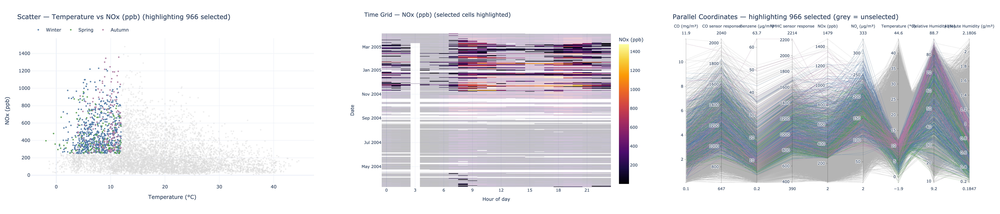

**G2: Elevated CO-NOx multi-pollutant profile** (1,710 hours lasso-selected in CO vs NOx)

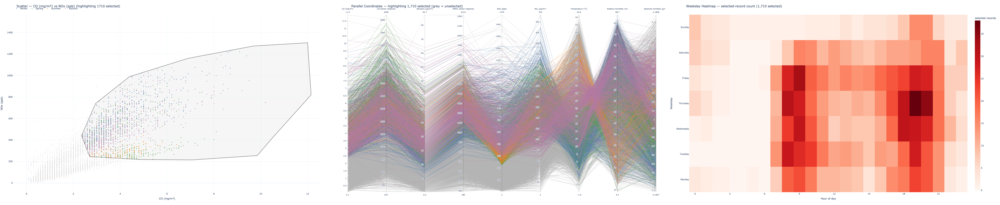

| Grouping | Members (hours / days) | Visual evidence (figure) | Defining attributes |
|---|---|---|---|
| G1 Cooler high-NOx | 966 hours, located mainly Nov 2004 to Mar 2005 in the time grid | Compact cool region above the NOx background (T vs NOx scatter); linked parallel coordinates; NOx time grid | Low T with elevated NOx |
| G2 Elevated CO-NOx | 1,710 hours, concentrated on weekday mornings 08-09 and evenings 18-20, fewer on weekends | Upper-right region of CO vs NOx scatter; linked parallel coordinates; weekday x hour count map | High CO, CO sensor, Benzene, NMHC sensor, NOx, NO2; T, RH, AH spread widely |

Full write-up: B's Task 1 report. Heuristic evaluation by B: `docs/task1/evaluation_report.md` (input for Task 4).

In [14]:
# Export Task 1 groupings G1 and G2 (member rows) to CSV for the report / other tasks.
from pathlib import Path

TASK1_OUT = PROJECT_ROOT / "output" / "task1"
TASK1_OUT.mkdir(parents=True, exist_ok=True)

task1_rows = df.dropna(subset=ATTRS).copy()

# G1: Cooler high-NOx profile (966 hours) - locked rule, matches B's time-grid digitisation.
g1_mask = (task1_rows["T"] < 12) & (task1_rows["NOx(GT)"] > 250)

# G2: Elevated CO-NOx profile - numeric proxy for the CO-vs-NOx upper-right lasso;
# the exact lasso vertices were not recorded, so the thresholds approximate the selection.
g2_mask = (task1_rows["CO(GT)"] > 2.5) & (task1_rows["NOx(GT)"] > 235)

g1 = task1_rows[g1_mask][["DateTime"] + ATTRS].sort_values("DateTime")
g2 = task1_rows[g2_mask][["DateTime"] + ATTRS].sort_values("DateTime")

g1.to_csv(TASK1_OUT / "G1_members.csv", index=False)
g2.to_csv(TASK1_OUT / "G2_members.csv", index=False)

print(f"G1 members: {len(g1):,}  ->  {TASK1_OUT / 'G1_members.csv'}")
print(f"G2 members: {len(g2):,}  ->  {TASK1_OUT / 'G2_members.csv'}")
print(f"Overlap (G1 & G2): {int((g1_mask & g2_mask).sum()):,} hours")

G1 members: 966  ->  /Users/elune/.codex/.chatgpt-projects/g-p-6a7ef148a9a881918404bb744ed74873/a2_d_work/execution_check_2026-11-05/run/COMP5048_A2_Runtime_518ef4d4d9/output/task1/G1_members.csv
G2 members: 1,718  ->  /Users/elune/.codex/.chatgpt-projects/g-p-6a7ef148a9a881918404bb744ed74873/a2_d_work/execution_check_2026-11-05/run/COMP5048_A2_Runtime_518ef4d4d9/output/task1/G2_members.csv
Overlap (G1 & G2): 529 hours


---
# 2. Task 2: Trend Analysis
**Owner: C (Nguyen Huu Hoang Duc)** · follows the groups found in Task 1

**Approach.** Six coordinated views track the Task 1 groups through the year. Views 2.1 to 2.4 follow hours of the day month by month: an animated scatterplot (2.1), monthly small multiples (2.2), monthly parallel coordinates showing membership and attribute change together (2.3), and an hour x attribute fingerprint (2.4). Views 2.5 and 2.6 look at whole days: a t-SNE and MDS projection (2.5) and monthly box plots (2.6). Findings are summarised at the end of the section.


### Task 2 setup
Uses the same data (`df`) and the same attributes (`ATTRS`) as Task 1. Hour band is an encoding helper only: it colours lines and points so we can see which hours move between groups. No clustering is used.

In [15]:
BAND_ORDER = ["Night 00-05", "Morning rush 06-10", "Midday 11-16", "Evening rush 17-21", "Late 22-23"]
BAND_COLORS = dict(zip(BAND_ORDER, ["#4a6fa5", "#e0823d", "#d8b23a", "#c4455a", "#7b5ea7"]))
band_of = lambda h: BAND_ORDER[0 if h <= 5 else 1 if h <= 10 else 2 if h <= 16 else 3 if h <= 21 else 4]

t2 = df.copy()
t2["Hour"] = t2["DateTime"].dt.hour
t2["MonthLabel"] = t2["DateTime"].dt.to_period("M").astype(str)
t2["HourBand"] = t2["Hour"].map(band_of)
MONTHS = sorted(t2["MonthLabel"].unique())

def discrete_scale(colors):
    n = len(colors); out = []
    for i, c in enumerate(colors):
        out += [[i / n, c], [(i + 1) / n, c]]
    return out
print(len(MONTHS), "months:", MONTHS[0], "to", MONTHS[-1])

14 months: 2004-03 to 2005-04


### View 2.1: Animated time-window view
Benzene vs NOx, one frame per week, coloured by hour band. Axes are fixed, so any movement between frames is real change. Press **Play** (or **Pause**) and watch where each colour sits as the year passes. Hover shows the record time, temperature (°C) and relative humidity (%).

**What to look for:** in spring and summer the rush-hour points (orange/red) stretch along a shallow line (lots of benzene, moderate NOx). In August they collapse into the low corner (holiday traffic). From September, and strongly from November, the same rush-hour points climb onto a much steeper line (far more NOx for the same benzene).

In [16]:
an = t2.dropna(subset=["C6H6(GT)", "NOx(GT)"]).sort_values("DateTime").copy()
an["Week"] = an["DateTime"].dt.to_period("W-SUN").dt.start_time.dt.strftime("%Y-%m-%d")
fig = px.scatter(an, x="C6H6(GT)", y="NOx(GT)", color="HourBand", animation_frame="Week",
                 color_discrete_map=BAND_COLORS, category_orders={"HourBand": BAND_ORDER},
                 range_x=[0, 65], range_y=[0, 1500], opacity=0.8, height=560,
                 hover_data={"DateTime": "|%Y-%m-%d %H:00", "T": ":.1f", "RH": ":.0f"},
                 labels={"C6H6(GT)": ATTR_LABELS["C6H6(GT)"], "NOx(GT)": ATTR_LABELS["NOx(GT)"], "HourBand": "Hour band",
                         "DateTime": "Record time", "T": ATTR_LABELS["T"], "RH": ATTR_LABELS["RH"], "Week": "Week starting"},
                 title="View 2.1: weekly frames, benzene vs NOx by hour band")
fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 350
fig.show()

### View 2.2: Monthly diurnal small multiples
One panel per month: median by hour of day (green) against the full-year median (grey). Shaded columns mark 06-10 and 17-21. Use the dropdown to change attribute. All 14 panels of one attribute share the same y range and ticks, so curve heights can be compared directly. Hover shows the month, hour and monthly median with its unit. Small multiples let all months be compared side by side, which complements the animation (animation alone relies on memory between frames).

In [17]:
ncol = 5; nrow = int(np.ceil(len(MONTHS) / ncol))
# Review fix P10: every panel of one attribute uses the same y range and tick spacing, so curve heights compare directly.
fig = make_subplots(rows=nrow, cols=ncol, subplot_titles=MONTHS, shared_yaxes=False,
                    horizontal_spacing=0.035, vertical_spacing=0.09)
yrange = {}
for a in ATTRS:
    year = t2.groupby("Hour")[a].median()
    prof = t2.groupby(["MonthLabel", "Hour"])[a].median().unstack()
    lo, hi = float(min(prof.min().min(), year.min())), float(max(prof.max().max(), year.max()))
    pad = 0.05 * (hi - lo)
    yrange[a] = [lo - pad, hi + pad]
    for j, m in enumerate(MONTHS):
        r, c = j // ncol + 1, j % ncol + 1
        mname = pd.Period(m).strftime("%B %Y")
        fmt = ".2f" if a in ("CO(GT)", "AH") else ".1f"
        fig.add_trace(go.Scatter(x=year.index, y=year.values, line=dict(color="#b8c2bf", width=1),
                                 visible=(a == "NOx(GT)"), showlegend=False,
                                 hovertemplate=f"Whole-period median, %{{x:02d}}:00<br>{ATTR_LABELS[a]}: %{{y:{fmt}}}<extra></extra>"), r, c)
        fig.add_trace(go.Scatter(x=prof.columns, y=prof.loc[m].values, line=dict(color="#0f7c6c", width=2),
                                 visible=(a == "NOx(GT)"), showlegend=False,
                                 hovertemplate=f"{mname}, %{{x:02d}}:00<br>Monthly median {ATTR_LABELS[a]}: %{{y:{fmt}}}<extra></extra>"), r, c)
n_axes = nrow * ncol
def yaxis_ranges(a):
    return {("yaxis" if k == 1 else f"yaxis{k}") + ".range": yrange[a] for k in range(1, n_axes + 1)}
per_attr = 2 * len(MONTHS)
buttons = [dict(label=ATTR_LABELS[a], method="update",
                args=[{"visible": [k // per_attr == i for k in range(len(fig.data))]},
                      {"title.text": f"View 2.2: diurnal profile by month, {ATTR_LABELS[a]} (same y range in every panel)",
                       **yaxis_ranges(a)}])
           for i, a in enumerate(ATTRS)]
for j in range(len(MONTHS)):
    for x0, x1 in [(6, 10), (17, 21)]:
        fig.add_vrect(x0=x0, x1=x1, fillcolor="#d6ece7", opacity=0.6, line_width=0, layer="below", row=j // ncol + 1, col=j % ncol + 1)
fig.update_xaxes(tickvals=[0, 6, 12, 18, 23], tickfont=dict(size=8))
fig.update_yaxes(range=yrange["NOx(GT)"], tickfont=dict(size=8), nticks=5)
fig.update_layout(height=620, title=f"View 2.2: diurnal profile by month, {ATTR_LABELS['NOx(GT)']} (same y range in every panel)",
                  updatemenus=[dict(buttons=buttons, active=ATTRS.index("NOx(GT)"), x=1.0, xanchor="right", y=1.12)])
fig.show()

### View 2.3: Membership + attribute change in one view (main evidence)
**Monthly parallel coordinates.** Each frame is one month. Each of the 24 lines is one hour of the day at its monthly median, coloured by hour band. Axis ranges are fixed across months. One view shows both kinds of change:
- **Membership change:** which coloured lines bundle together (e.g. do the yellow midday lines sit with the low night bundle or with the high rush-hour bundle?).
- **Defining-attribute change:** on which axes the high bundle sits (benzene/CO/NMHC high in summer; NOx/NO2 high with low T and AH in winter).

Press **Play** / **Pause**, or click or drag the month slider to jump to a month. Axis names are shortened with units (key above the chart). Brush the Hour axis (for example 11-16) to highlight a set of hours; click outside the brushed range to clear it.

In [18]:
prof_all = t2.groupby(["MonthLabel", "Hour"])[ATTRS].median()
rng = {a: [float(prof_all[a].min()), float(prof_all[a].max())] for a in ATTRS}
hour_codes = [BAND_ORDER.index(band_of(h)) for h in range(24)]
# Review fix P11: short axis names with units so the ten axis titles no longer overlap (full names in the key below).
PC_LABELS = {"CO(GT)": "CO mg/m³", "PT08.S1(CO)": "S1 CO", "C6H6(GT)": "C6H6 µg/m³", "PT08.S2(NMHC)": "S2 NMHC",
             "NOx(GT)": "NOx ppb", "NO2(GT)": "NO₂ µg/m³", "T": "T °C", "RH": "RH %", "AH": "AH g/m³"}

def month_pc(m):
    p = prof_all.loc[m].reindex(range(24))
    dims = [dict(label="Hour", values=list(range(24)), range=[0, 23])] + \
           [dict(label=PC_LABELS[a], values=p[a].values, range=rng[a]) for a in ATTRS]
    return go.Parcoords(dimensions=dims, labelfont=dict(size=12), tickfont=dict(size=10),
                        line=dict(color=hour_codes, colorscale=discrete_scale(list(BAND_COLORS.values())),
                                  cmin=-0.5, cmax=len(BAND_ORDER) - 0.5))

fig = go.Figure(data=[month_pc(MONTHS[0])], frames=[go.Frame(data=[month_pc(m)], name=m) for m in MONTHS])
fig.update_layout(
    title="View 2.3: hourly median profiles by month (24 lines = 24 hours, colour = hour band)",
    height=640, margin=dict(l=50, r=50, t=90, b=200),
    annotations=[dict(text="S1 CO = CO sensor response, S2 NMHC = NMHC sensor response, T = temperature, RH = relative humidity, AH = absolute humidity",
                      xref="paper", yref="paper", x=0, y=-0.47, showarrow=False, xanchor="left", font=dict(size=11, color="#555")),
                 dict(text="Play / Pause, or click or drag the month slider to jump to a month (this also pauses playback)", xref="paper", yref="paper", x=0, y=-0.41, showarrow=False, xanchor="left", font=dict(size=11, color="#555"))],
    updatemenus=[dict(type="buttons", direction="left", x=0, y=-0.1, xanchor="left", yanchor="top", pad=dict(t=0, r=10), buttons=[
        dict(label="Play", method="animate", args=[None, {"frame": {"duration": 900, "redraw": True}, "fromcurrent": True}]),
        dict(label="Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate", "transition": {"duration": 0}}])])],
    sliders=[dict(x=0.17, y=-0.1, yanchor="top", len=0.83, pad=dict(t=0), currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=m, method="animate",
                              args=[[m], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]) for m in MONTHS])])
fig.show()
print("Colour key:", BAND_COLORS)

Colour key: {'Night 00-05': '#4a6fa5', 'Morning rush 06-10': '#e0823d', 'Midday 11-16': '#d8b23a', 'Evening rush 17-21': '#c4455a', 'Late 22-23': '#7b5ea7'}


### View 2.4: Hour x attribute fingerprint by month (same two changes, second encoding)
Rows = hours, columns = attributes. Colour = how far that hour's monthly median sits above (red) or below (blue) the attribute's full-year median, in IQR units (robust to outliers and comparable across units). A **row turning red** = that hour joined the polluted group (membership). A **column turning red** = that attribute joined the defining combination. Press **Play** / **Pause**, or click or drag the month slider to jump to a month (this also pauses). Hover gives the month, hour, attribute and the deviation in IQR units. White cells at 03:00 for NOx/NO2 are the known missing-data gap.

In [19]:
med_all = t2[ATTRS].median()
iqr_all = t2[ATTRS].quantile(0.75) - t2[ATTRS].quantile(0.25)
xlabels = ["CO", "S1<br>(CO)", "C6H6", "S2<br>(NMHC)", "NOx", "NO2", "T", "RH", "AH"]   # short horizontal labels (Week 8: angled text is harder to read)
def fingerprint_raw(m):
    return (prof_all.loc[m].reindex(range(24)) - med_all) / iqr_all
def fingerprint(m):
    return fingerprint_raw(m).clip(-2, 2)
def hover_text(m):
    # Review fix P13: hover names the month, hour and attribute and explains the value.
    raw = fingerprint_raw(m); mname = pd.Period(m).strftime("%B %Y")
    return [[(f"Month: {mname}<br>Hour: {h:02d}:00<br>Attribute: {ATTR_LABELS[a]}<br>"
              + ("No data (missing readings)" if pd.isna(raw.loc[h, a]) else
                 f"Deviation from whole-period median: {raw.loc[h, a]:+.2f} IQR<br>(monthly median at this hour, in interquartile-range units)"))
             for a in ATTRS] for h in range(24)]
def hm(m):
    return go.Heatmap(z=fingerprint(m).values, x=xlabels, y=list(range(24)), zmin=-2, zmax=2,
                      text=hover_text(m), hovertemplate="%{text}<extra></extra>",
                      colorscale="RdBu_r", colorbar=dict(title="vs whole-period<br>median (IQR units)"))
fig = go.Figure(data=[hm(MONTHS[0])], frames=[go.Frame(data=[hm(m)], name=m) for m in MONTHS])
fig.update_layout(title="View 2.4: hour x attribute fingerprint", height=700, margin=dict(b=150),
    yaxis=dict(autorange="reversed", title="Hour of day", dtick=2), xaxis=dict(tickangle=0),
    annotations=[dict(text="Play / Pause, or click or drag the month slider to jump to a month (this also pauses playback)", xref="paper", yref="paper", x=0, y=1.06, showarrow=False, xanchor="left", font=dict(size=11, color="#555"))],
    updatemenus=[dict(type="buttons", direction="left", x=0, y=-0.1, xanchor="left", yanchor="top", pad=dict(t=0, r=10), buttons=[
        dict(label="Play", method="animate", args=[None, {"frame": {"duration": 900, "redraw": True}, "fromcurrent": True}]),
        dict(label="Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate", "transition": {"duration": 0}}])])],   # review fix P12: explicit Pause button plus the slider hint
    sliders=[dict(x=0.17, y=-0.1, yanchor="top", len=0.83, pad=dict(t=0), currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=m, method="animate",
                              args=[[m], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]) for m in MONTHS])])
fig.show()

In [20]:
# Numbers quoted in the findings, read off View 2.4 (IQR units) and View 2.2 (NOx medians)
for m in ["2004-07", "2004-08", "2004-11", "2005-02"]:
    print(m); display(fingerprint(m).loc[[8, 13, 19, 23]].round(1))
display(prof_all["NOx(GT)"].unstack().loc[:, [0, 8, 13, 19]].round(0))

2004-07


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.9,0.7,1.8,1.4,0.4,0.2,0.5,-0.2,0.5
13,0.1,-0.2,0.2,0.2,-0.3,0.0,1.6,-1.2,0.2
19,0.8,0.1,0.9,0.7,-0.1,0.4,1.2,-1.0,0.1
23,0.1,0.1,0.3,0.3,-0.3,-0.1,0.7,-0.4,0.5


2004-08


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,-0.1,0.1,0.5,0.4,-0.3,-0.7,0.6,0.2,1.3
13,-0.4,-0.5,-0.3,-0.3,-0.6,-0.7,1.4,-0.8,1.0
19,-0.1,-0.1,0.0,0.0,-0.5,-0.4,1.0,-0.5,1.2
23,-0.2,-0.1,-0.1,-0.1,-0.5,-0.6,0.7,0.1,1.3


2004-11


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.4,0.6,0.8,0.7,1.2,0.2,-0.6,0.8,-0.1
13,0.4,0.4,0.4,0.3,1.0,0.5,-0.2,-0.0,0.0
19,1.4,0.8,1.3,1.0,1.3,0.8,-0.3,0.3,0.0
23,0.0,-0.0,-0.1,-0.1,0.4,-0.1,-0.5,0.7,-0.1


2005-02


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.3,0.5,0.3,0.3,1.2,1.5,-1.1,0.5,-0.9
13,-0.1,-0.1,-0.2,-0.2,0.2,0.5,-0.6,-0.5,-0.9
19,0.8,0.4,0.4,0.4,0.9,1.5,-0.8,-0.3,-0.9
23,-0.1,-0.0,-0.3,-0.3,0.2,0.8,-0.9,-0.0,-0.9


Hour,0,8,13,19
MonthLabel,,,,
2004-03,104.0,230.0,149.0,208.0
2004-04,83.0,215.0,150.0,197.0
2004-05,98.0,203.0,115.0,164.0
2004-06,91.0,232.0,108.0,173.0
2004-07,111.0,262.0,111.0,155.0
2004-08,62.0,101.0,54.0,70.0
2004-09,152.0,478.0,273.0,460.0
2004-10,209.0,455.0,368.0,526.0
2004-11,234.0,464.0,416.0,484.0


### View 2.5: Day-level projection (spatialisation with MDS and t-SNE)
Each point is one **day**, described by the daily median of the nine attributes, scaled by median and IQR so every attribute counts equally. The nine-dimensional days are placed in 2D so that similar days sit close together (Week 7 spatialisation, Week 10 MDS). Two methods are shown side by side because the lectures stress their different strengths:
- **MDS** keeps global distances, so the overall drift of days through the year is trustworthy.
- **t-SNE** keeps local neighbourhoods, so tight groups of similar days stand out, but distances *between* groups are not meaningful.

This is dimension reduction, not clustering: no group labels are computed. Colour = date (blue Mar 2004 to red Apr 2005), diamonds = weekends, the thin grey line joins consecutive days so the path of the year can be followed. Hover shows the date.

In [21]:
from sklearn.manifold import MDS, TSNE

day = t2.groupby(t2["DateTime"].dt.normalize())[ATTRS].median().dropna()
day_z = (day - day.median()) / (day.quantile(0.75) - day.quantile(0.25))
emb_mds = MDS(n_components=2, random_state=0, n_init=4, normalized_stress="auto").fit_transform(day_z)
emb_tsne = TSNE(n_components=2, random_state=0, perplexity=30, init="pca").fit_transform(day_z)
proj = pd.DataFrame({"mds_x": emb_mds[:, 0], "mds_y": emb_mds[:, 1], "tsne_x": emb_tsne[:, 0], "tsne_y": emb_tsne[:, 1]}, index=day.index)
proj["Month"] = proj.index.to_period("M").astype(str)
proj["Weekend"] = proj.index.dayofweek >= 5
proj["DayNo"] = (proj.index - proj.index.min()).days
print(len(proj), "complete days")

fig = make_subplots(rows=1, cols=2, subplot_titles=["MDS (global distances)", "t-SNE (local neighbourhoods)"], horizontal_spacing=0.06)
for c, (xs, ys) in enumerate([("mds_x", "mds_y"), ("tsne_x", "tsne_y")], 1):
    fig.add_trace(go.Scatter(x=proj[xs], y=proj[ys], mode="lines", line=dict(color="rgba(150,150,150,0.25)", width=1),
                             hoverinfo="skip", showlegend=False), 1, c)
    fig.add_trace(go.Scatter(x=proj[xs], y=proj[ys], mode="markers",
                             marker=dict(color=proj["DayNo"], colorscale="Turbo", size=7,
                                         symbol=np.where(proj["Weekend"], "diamond", "circle"),
                                         line=dict(width=0.5, color="white"),
                                         colorbar=dict(title="Date", tickvals=[0, 92, 184, 275, 365],
                                                       ticktext=["Mar 04", "Jun 04", "Sep 04", "Dec 04", "Mar 05"]) if c == 2 else None,
                                         showscale=(c == 2)),
                             text=proj.index.strftime("%a %d %b %Y"), hovertemplate="%{text}<extra></extra>", showlegend=False), 1, c)
fig.update_xaxes(showticklabels=False); fig.update_yaxes(showticklabels=False)
fig.update_layout(title="View 2.5: days projected to 2D (colour = date, diamond = weekend)", height=520)
fig.show()

341 complete days


**Animated version.** Press Play (Pause stops it): each frame highlights one month's days on the t-SNE map (others grey). Watch the highlighted days move from one region to another as the seasons change, and note the jump in early November 2004.

In [22]:
frames = []
def month_traces(m):
    cur = proj[proj["Month"] == m]
    return [go.Scatter(x=proj["tsne_x"], y=proj["tsne_y"], mode="markers", marker=dict(color="#d0d6d4", size=6), hoverinfo="skip"),
            go.Scatter(x=cur["tsne_x"], y=cur["tsne_y"], mode="markers+lines",
                       marker=dict(color="#c4455a", size=9, symbol=np.where(cur["Weekend"], "diamond", "circle")),
                       line=dict(color="rgba(196,69,90,0.4)", width=1),
                       text=cur.index.strftime("%a %d %b"), hovertemplate="%{text}<extra></extra>")]
months_p = sorted(proj["Month"].unique())
fig = go.Figure(data=month_traces(months_p[0]), frames=[go.Frame(data=month_traces(m), name=m) for m in months_p])
fig.update_layout(title="View 2.5b: t-SNE map, one month highlighted per frame", height=560, showlegend=False,
    xaxis=dict(showticklabels=False), yaxis=dict(showticklabels=False),
    updatemenus=[dict(type="buttons", x=0, y=-0.08, xanchor="left", buttons=[
        dict(label="Play", method="animate", args=[None, {"frame": {"duration": 900, "redraw": True}, "fromcurrent": True}]),
        dict(label="Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate", "transition": {"duration": 0}}])])],
    sliders=[dict(x=0.14, y=-0.05, len=0.86, currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=m, method="animate", args=[[m], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]) for m in months_p])])
fig.show()

# where the late-Oct / early-Nov days sit (used in the findings)
display(proj.loc["2004-10-28":"2004-11-15", ["tsne_x", "tsne_y"]].round(1).T)

DateTime,2004-10-28,2004-10-29,2004-10-30,2004-10-31,2004-11-01,2004-11-02,2004-11-03,2004-11-04,2004-11-05,2004-11-06,2004-11-07,2004-11-08,2004-11-10,2004-11-11,2004-11-12,2004-11-13,2004-11-14,2004-11-15
tsne_x,11.1,10.5,13.5,-6.4,13.1,18.5,11.8,15.7,14.1,11.3,-12.6,-4.5,6.0,15.7,0.9,2.4,-11.7,-2.2
tsne_y,3.7,2.9,3.4,2.7,5.1,1.6,4.9,3.3,4.1,4.4,-6.0,-7.4,-11.0,-4.7,-3.2,-2.8,-8.5,-11.2


### View 2.6: Monthly distributions (box plots)
Box plots by month (Week 7 distribution analysis) show the shift of the whole distribution, not only the median: the NOx box jumps up from September, benzene falls in winter, and T and AH drop together in November.

In [23]:
fig = make_subplots(rows=2, cols=2, subplot_titles=[ATTR_LABELS[a] for a in ["NOx(GT)", "C6H6(GT)", "T", "AH"]],
                    vertical_spacing=0.14, horizontal_spacing=0.07)
for k, a in enumerate(["NOx(GT)", "C6H6(GT)", "T", "AH"]):
    r, c = k // 2 + 1, k % 2 + 1
    fig.add_trace(go.Box(x=t2["MonthLabel"], y=t2[a], marker=dict(size=2, color="#0f7c6c"), line=dict(width=1),
                         boxpoints=False, showlegend=False), r, c)
fig.update_xaxes(type="category", tickvals=MONTHS[::2], ticktext=[m[2:] for m in MONTHS[::2]], tickangle=0)
fig.update_layout(title="View 2.6: monthly distribution of key attributes", height=620)
fig.show()

### Task 2 findings (C)

**Membership changes**

Red cells and raised curves show changes in an hour's monthly profile. Actual membership is counted against the Task 1 group rules (G1: T < 12 °C and NOx > 250 ppb; G2: CO > 2.5 mg/m³ and NOx > 235 ppb).

| Change | When | Visual evidence |
|---|---|---|
| Midday hours (11-16) move into G2, later G1 | From Sep-Oct 2004, strongest Oct 2004 to Jan 2005 | View 2.4: 13:00 row turns red (NOx -0.3 in Jul → +1.0 in Nov). View 2.3: yellow lines leave the low bundle and join the rush-hour lines. View 2.2: midday NOx plateau about 110 in Jun-Jul vs 370-480 in Oct-Jan. Counted members: under 10% of midday hours meet G2 from Mar to Aug, 38% in Sep, 67% in Oct; 11-33% also meet G1 from Nov, none before |
| Late hours (22-00) move into G1 | Winter (Nov 2004 to Feb 2005) | View 2.2: NOx at 00:00 about 90-110 in Mar-Jul vs 210-315 in Oct-Mar. View 2.4: 23:00 row turns pink in Nov (NOx +0.4) and Feb (NO2 +0.8). Counted members: 35-51% of 22:00-00:00 hours meet G1 from Nov to Feb, none from Apr to Oct |
| Rush hours leave the traffic group, then return | Mid-August 2004 → early September | View 2.1: weekday rush points collapse into the low corner for the August weeks and return in September. View 2.4: 08:00 row fades from strong red in Jul (benzene +1.8) to near neutral in Aug (+0.5, NO2 -0.7). NOx at 08:00 drops 262 → 101. Counted members: weekday 08:00 hours meeting G2 fall from 92% in Jul to 9% in Aug, back to 86% in Sep |

**Defining-attribute changes** (08:00 rush-hour group, View 2.4)

| Month | Defining combination |
|---|---|
| Jul 2004 | Benzene +1.8, NMHC sensor +1.4, CO +0.9; NOx only +0.4; warm (T +0.5), dry |
| Nov 2004 | NOx leads (+1.2); benzene down to +0.8; humid (RH +0.8), cooler (T -0.6) |
| Feb 2005 | NO2 +1.5 and NOx +1.2 lead; benzene only +0.3; cold and dry air (T -1.1, AH -0.9) |

**Summary:** the traffic group changes from **benzene/CO/NMHC + warm + dry** in the warm season to **NOx/NO2 + cold + humid (low AH)** in the cold season. View 2.1 shows the same switch as rush-hour points moving from a shallow benzene-NOx line onto a steep one. These seasonal changes provide context for Task 3, which examines an hourly departure from the cool, high-NOx group within the cold-season period.

**Day-level projection (View 2.5, 2.6).** On the t-SNE map the days form separate regions by season: spring days, summer days (June to July), a detached group of mid-August holiday days, autumn days (October to early November) and winter days. Playing the monthly animation, the highlighted days move steadily from one region to the next, which is the membership change at day level. The clearest break is between 6 and 7 November 2004: up to 6 November the days sit with the October group, and from 7 November they jump to the winter region and stay there. MDS shows the same ordering as a smooth drift, which supports reading the break as a change in the data rather than a t-SNE effect. The original attributes agree: daily median AH falls from 1.29 on 6 November to 0.74 on 7 November and T from about 19 °C to 8-11 °C over the next three days, while NOx rises again from 8 November. The box plots (View 2.6) confirm that the whole distribution moves, not just the median: the NOx box rises sharply from September, while T and AH drop together in November.

### Literature survey (C)
| Reference | Supports |
|---|---|
| Inselberg, A. (1985). The plane with parallel coordinates. *The Visual Computer*, 1(2), 69-91. | Parallel coordinates for multivariate groups (View 1.2, View 2.3) |
| Heinrich, J., & Weiskopf, D. (2013). State of the art of parallel coordinates. *Eurographics 2013 STAR*, 95-116. | Overplotting, axis ordering, brushing in parallel coordinates |
| Becker, R. A., & Cleveland, W. S. (1987). Brushing scatterplots. *Technometrics*, 29(2), 127-142. | Brushing and linking (Task 1 dashboard) |
| Tufte, E. R. (1990). *Envisioning Information*. Graphics Press. | Small multiples (View 2.2) |
| Robertson, G., Fernandez, R., Fisher, D., Lee, B., & Stasko, J. (2008). Effectiveness of animation in trend visualization. *IEEE TVCG*, 14(6), 1325-1332. | Animation vs small multiples for trends (View 2.1 + 2.2 used together) |
| Van Wijk, J. J., & Van Selow, E. R. (1999). Cluster and calendar based visualization of time series data. *Proc. IEEE InfoVis '99*, 4-9. | Calendar / day x hour views (View 1.1, View 2.4) |
| Aigner, W., Miksch, S., Schumann, H., & Tominski, C. (2011). *Visualization of Time-Oriented Data*. Springer. | Design of temporal views |
| Munzner, T. (2014). *Visualization Analysis and Design*. CRC Press. | Marks and channels, colour choices, nested evaluation model (Task 4) |
| De Vito, S., Massera, E., Piga, M., Martinotto, L., & Di Francia, G. (2008). On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario. *Sensors and Actuators B: Chemical*, 129(2), 750-757. | Source of the UCI Air Quality dataset |
| Torgerson, W. S. (1952). Multidimensional scaling: I. Theory and method. *Psychometrika*, 17(4), 401-419. | MDS projection (View 2.5) |
| van der Maaten, L., & Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine Learning Research*, 9, 2579-2605. | t-SNE projection (View 2.5) |

# 3. Task 3: Critical Moment and What-if Analysis
**Owner: A (Wang Yuyao)**

### Recovered G1 and conditional preservation

We recovered the original Task 1 G1 from B's selected-hour time-grid image. On the shared complete records, its 966 observations match **T < 12°C and NOx > 250 ppb** exactly. This replaces the earlier inclusive G1-A definition and its interpretation of the 20:00 event. Task 1 identified the group visually; the strict rule reconstructs the membership shown in that image.

The analysis retains all nine attributes and DateTime, with missing values left unchanged. Because the dates and earlier results had already been inspected, this reanalysis is exploratory. The recovered membership comes from the image, not a raw lasso export.


In [24]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown
if 'PROJECT_ROOT' not in globals():
    raise RuntimeError('Run the first bundled-resource cell before Task 3.')
ROOT = PROJECT_ROOT
OUT = ROOT / 'output/task3/stage5'
RECOMPUTE = False
if RECOMPUTE:
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT/'run_g1_reanalysis.py'), '--recompute'], cwd=ROOT, check=True)
results = json.loads((OUT/'results.json').read_text(encoding='utf-8'))
print('Recovered G1 members:', results['members'])
print('Definition:', results['definition'])
print('Primary exit:', results['primary_time'])
print('Selected model:', results['selected_model'])

Recovered G1 members: 966
Definition: T < 12 C and NOx > 250 ppb
Primary exit: 2004-11-11 19:00:00
Selected model: weather_hgb


### 3.1 Recover the original group and verify membership

The source `A3_timegrid_NOx.png` places each selected observation at a date and hour. Its 391 day rows and 24 hour columns let us digitise membership without using T or NOx as inputs to the image classifier. We used the original renderer to locate the plot and recorded pixel-colour rules to separate selected cells from faded context. Thresholds of 125, 130 and 135 all recover the same 966 timestamps.

The recovered labels match the strict rule exactly: the intersection and union both contain 966 timestamps, Jaccard similarity is 1.000, and there are no differences. The old inclusive definition adds 17 records: 14 at T = 12°C and 3 additional records at NOx = 250 ppb. Its Jaccard similarity to the original selection is 966/983 = 0.982706. The CSV records each timestamp, source pixel, RGB value and label.

The reconstruction uses a raster image because the original lasso vertices are unavailable. We include the figure and method so the recovered membership can be checked.


In [25]:
audit = pd.read_csv(OUT/'audit/membership_audit.csv', parse_dates=['DateTime'])
complete = audit.dropna(subset=['CO(GT)','PT08.S1(CO)','C6H6(GT)','PT08.S2(NMHC)','NOx(GT)','NO2(GT)','T','RH','AH'])
display(pd.DataFrame([
    {'Definition':'Recovered B selection','Members':int(complete.B_G1_digitized.sum())},
    {'Definition':'T < 12 and NOx > 250','Members':int(complete.strict_G1.sum())},
    {'Definition':'Earlier inclusive G1-A','Members':int(complete.old_G1A.sum())}]))
assert (complete.B_G1_digitized == complete.strict_G1).all()
display(pd.read_csv(OUT/'audit/seventeen_boundary_records.csv'))
display(pd.read_csv(OUT/'audit/attribute_profile_comparison.csv'))

,Definition,Members
0,Recovered B selection,966
1,T < 12 and NOx > 250,966
2,Earlier inclusive G1-A,983


,row_id,DateTime,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
0,806,2004-04-13 08:00:00,4.5,1452.0,22.1,1354.0,282.0,128.0,12.0,58.1,0.8138
1,5892,2004-11-11 06:00:00,1.1,952.0,6.1,814.0,250.0,89.0,8.3,77.2,0.8464
2,5905,2004-11-11 19:00:00,3.5,1189.0,16.1,1183.0,463.0,166.0,12.0,73.3,1.0264
3,6003,2004-11-15 21:00:00,2.4,904.0,8.6,924.0,355.0,147.0,12.0,34.3,0.4787
4,6103,2004-11-20 01:00:00,2.7,695.0,4.0,709.0,264.0,126.0,12.0,14.5,0.2029
5,6475,2004-12-05 13:00:00,2.4,1100.0,6.7,842.0,309.0,89.0,12.0,80.0,1.1167
6,6480,2004-12-05 18:00:00,2.4,1120.0,8.9,935.0,275.0,93.0,12.0,78.4,1.0954
7,6665,2004-12-13 11:00:00,4.8,1422.0,22.4,1362.0,920.0,214.0,12.0,45.9,0.6421
8,7350,2005-01-11 00:00:00,1.8,1205.0,7.7,888.0,256.0,116.0,12.0,71.9,1.0071
9,7372,2005-01-11 22:00:00,3.4,1415.0,16.6,1197.0,559.0,146.0,12.0,67.4,0.9417


,group,attribute,n,median,q25,q75
0,B_G1_digitized,CO(GT),966,2.7000,2.00000,3.9000
1,B_G1_digitized,PT08.S1(CO),966,1192.0000,1084.00000,1359.2500
2,B_G1_digitized,C6H6(GT),966,11.2000,7.80000,16.8000
3,B_G1_digitized,PT08.S2(NMHC),966,1023.0000,892.25000,1204.0000
4,B_G1_digitized,NOx(GT),966,424.5000,324.25000,613.0000
5,B_G1_digitized,NO2(GT),966,169.0000,140.00000,198.0000
6,B_G1_digitized,T,966,8.0000,5.80000,10.0000
7,B_G1_digitized,RH,966,59.4500,44.10000,73.0750
8,B_G1_digitized,AH,966,0.6134,0.44505,0.7633
9,strict_G1,CO(GT),966,2.7000,2.00000,3.9000


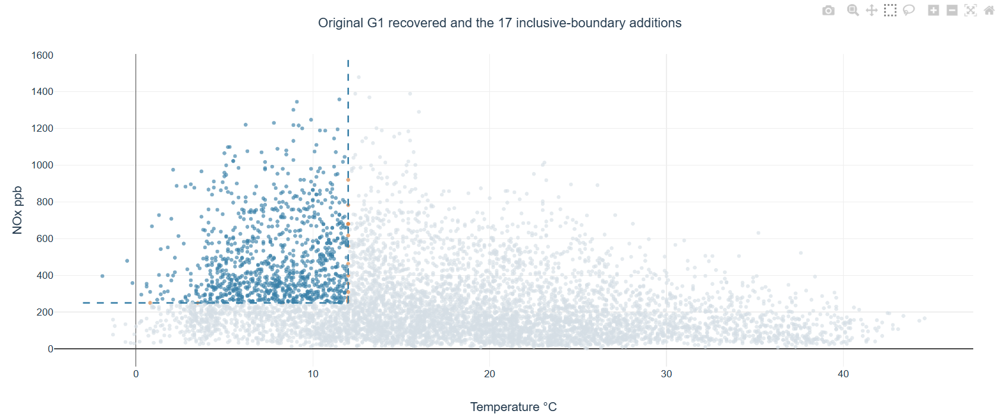

Figure 1. Recovered original G1 in blue, the 17 inclusive-boundary additions in orange and all remaining complete observations in grey. The strict temperature and NOx boundaries reconstruct the digitised group.

### 3.2 Identify the critical moment

At **18:00 on 11 November 2004**, T = 11.6°C and NOx = 573 ppb, placing the observation inside recovered G1. At **19:00**, T rises to 12.0°C while NOx is 463 ppb. This 0.4°C increase crosses the strict temperature boundary and marks the evening exit. By 20:00, the observation is already outside G1, so the earlier interpretation of an exit between 19:00 and 20:00 no longer applies.

We retain all three exits on the inspected day. The 02:00 exit follows a NOx drop, 13:00 is an earlier temperature crossing, and 19:00 is the primary evening crossing. We identified the new event from observed membership before querying the new scenario predictions. Task 2 provides seasonal context, but its broader day-level change is distinct from this hourly event.

The six-hour window before the event contains two G1 observations (2 of 6 hours); the six-hour window after it contains none (0 of 6). The selected event therefore describes the single-hour transition from inside G1 at 18:00 to outside at 19:00. It does not represent departure from a group that had remained stable for six continuous hours.


In [26]:
display(pd.read_csv(OUT/'all_observed_exits.csv')[['DateTime','T','NOx(GT)','G1_member']])
members = pd.read_csv(OUT/'G1_memberships.csv', parse_dates=['DateTime'])
display(members[members.DateTime.between('2004-11-11 17:00','2004-11-11 21:00')])
display(pd.read_csv(OUT/'before_after_windows.csv'))

,DateTime,T,NOx(GT),G1_member
0,2004-11-11 02:00:00,9.2,219.0,False
1,2004-11-11 13:00:00,12.5,557.0,False
2,2004-11-11 19:00:00,12.0,463.0,False


,row_id,DateTime,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH,G1_member
4019,5903,2004-11-11 17:00:00,2.8,1109.0,11.2,1021.0,395.0,168.0,11.5,78.1,1.0565,True
4020,5904,2004-11-11 18:00:00,3.9,1201.0,16.5,1196.0,573.0,187.0,11.6,76.0,1.0354,True
4021,5905,2004-11-11 19:00:00,3.5,1189.0,16.1,1183.0,463.0,166.0,12.0,73.3,1.0264,False
4022,5906,2004-11-11 20:00:00,4.7,1282.0,20.6,1312.0,568.0,177.0,12.9,68.8,1.0175,False
4023,5907,2004-11-11 21:00:00,4.6,1207.0,16.8,1203.0,706.0,207.0,13.1,69.6,1.0464,False


,window,start,end_exclusive,n,members,T_median,RH_median,AH_median,NOx_median
0,before,2004-11-11 13:00:00,2004-11-11 19:00:00,6,2,12.35,74.45,1.04585,565.0
1,after,2004-11-11 19:00:00,2004-11-12 01:00:00,6,0,12.80,70.45,1.03790,328.0


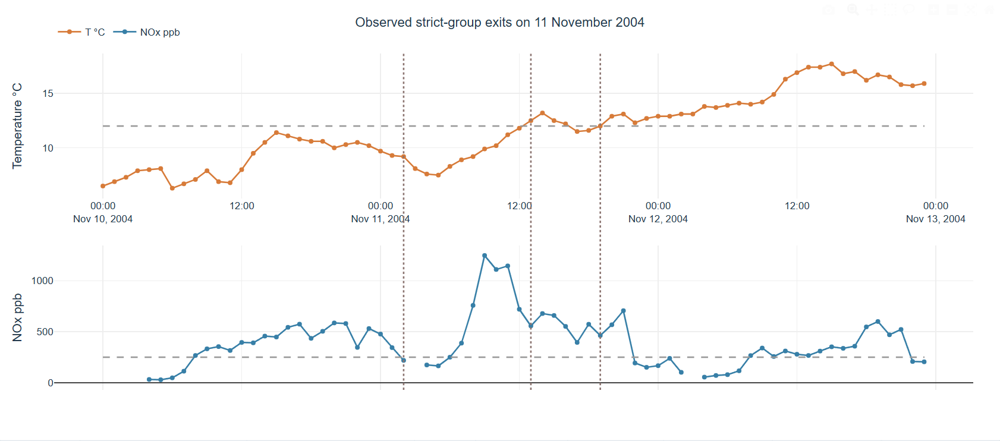

Figure 2. Original hourly temperature and NOx with strict group boundaries. The evening exit occurs at 19:00; missing observations remain gaps.

Temperature and NOx use the same time axis and separate vertical panels, keeping their original units. Threshold lines mark the G1 criteria, and event markers show the observed departures, so temperature-driven and NOx-driven exits can be distinguished.


### 3.3 Refit and validate the dynamic regression

We use three fixed model families: Ridge, histogram gradient boosting and ExtraTrees, each with a history/calendar control. Exact timestamp joins supply the previous one and two hours for all nine attributes. The models predict increments in six pollutant/sensor responses, with current T, RH and AH as scenario inputs. Current pollutant values are neither model inputs nor residuals added back to predictions.

Model selection now targets NOx, the pollutant used to define G1. Across four forward validation folds from July to October, gradient boosting has the lowest mean NOx MAE at 43.49 ppb, followed by ExtraTrees at 43.70 ppb. Each fold has a 24-hour gap between training and validation, and final training ends on 29 October 2004. History-only ExtraTrees has an MAE of 43.72 ppb, compared with 53.94 ppb for persistence. Weather therefore adds only a modest average prediction benefit. The validation and uncertainty results below use gradient boosting; Ridge and ExtraTrees provide scenario comparisons. Because the dates had already been inspected, the analysis remains exploratory.

For 7 to 13 November, the selected model has a NOx R² of 0.753, an MAE of 74.07 ppb and strict membership accuracy of 97.41% (28 true positives, 85 true negatives, 1 false positive and 2 false negatives). The earlier event block contains no positive members, so its perfect membership accuracy does not test performance on the positive class.


In [27]:
display(pd.read_csv(OUT/'model_selection.csv'))
display(pd.read_csv(ROOT/'output/task3/stage4/dynamic_fold_ranges.csv'))
validation = pd.read_csv(OUT/'validation.csv')
display(validation[validation.model == results['selected_model']])

,model,forward_fold_NOx_MAE
0,weather_hgb,43.488151
1,weather_extra,43.704603
2,history_extra,43.724859
3,history_hgb,44.082292
4,weather_ridge,48.264791
5,history_ridge,48.687526
6,persistence,53.944192


,fold,train_n,train_end,valid_start,valid_end,valid_n
0,jul,1826,2004-06-29 23:00:00,2004-07-01 00:00:00,2004-07-31 23:00:00,481
1,aug,2311,2004-07-26 02:00:00,2004-08-01 00:00:00,2004-08-31 23:00:00,361
2,sep,2682,2004-08-28 13:00:00,2004-09-01 00:00:00,2004-09-30 23:00:00,388
3,oct,3067,2004-09-29 23:00:00,2004-10-01 00:00:00,2004-10-28 23:00:00,270


,model,split,n,tn,fp,fn,tp,accuracy,r2,mae,error90_coverage
15,weather_hgb,event_after,116,85,1,2,28,0.974138,0.753201,74.068394,0.784483
16,weather_hgb,event_before,133,133,0,0,0,1.000000,0.706921,71.721204,0.766917
17,weather_hgb,reused_jan_apr,1522,988,46,79,409,0.917871,0.792005,61.692987,0.809461


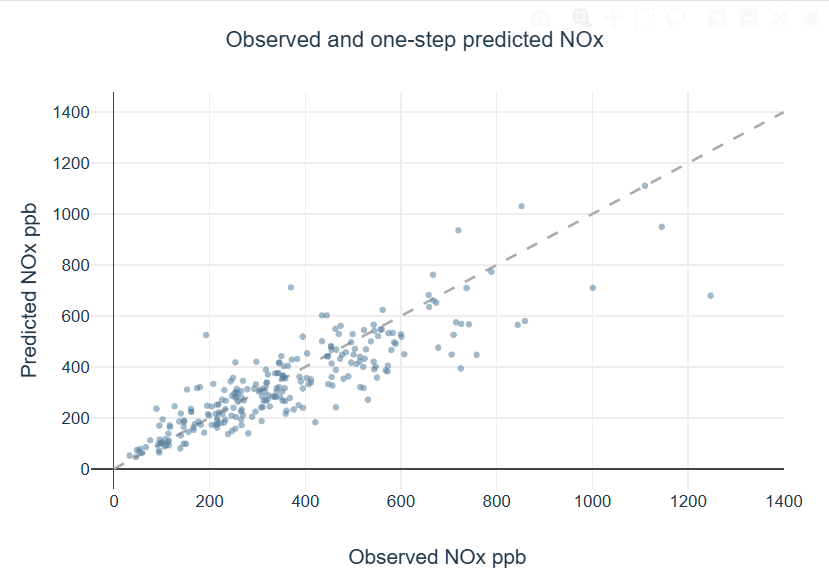

Figure 3. Observed and one-step predicted NOx around the event. This evaluates forecasts under observed weather; it does not validate an intervention.

### 3.4 Test alternatives for the recovered G1

For 19:00, we hold the previous two observed hours fixed and lower T by 2°C, keeping RH at 73.3%. AH is derived from the training humidity relation. This gives an alternative of **T = 10.0°C, RH = 73.3%, AH = 0.90115** dataset units.

Gradient boosting predicts NOx of **504.78 ppb**, compared with **546.75 ppb** for Ridge and **570.32 ppb** for ExtraTrees. All three predictions satisfy the recovered G1 condition and pass the checks for physical validity, historical weather support and every lagged-attribute range. With no temperature change, the predicted point has T = 12.0°C and remains outside G1. We save all fixed scenarios and the full grid, including failed cells. The 20:00 result is kept as a comparison for an observation that is already outside G1.

Temperature directly defines one of the membership criteria, so predicted re-entry partly follows from moving below 12°C. The NOx predictions provide additional conditional evidence. The parallel-coordinates plot and attribute table show all six predicted responses; the analysis neither requires nor claims complete preservation of the other attributes.

#### Additional supported alternatives

The ΔT × ΔAH grid tests alternatives beyond the primary fixed-RH scenario. Here, temperature and absolute humidity are adjusted, and relative humidity is derived from the fitted humidity relationship. We assess each combination against the same strict G1 definition and check physical validity, historical weather support and lag-range support. The map shows the selected model's results, while the scenario panel compares all three weather models.

The examples below come from the saved grid for **19:00 on 11 November 2004**. For each combination, all three models pass the declared support checks and predict G1 membership. The NOx values are from the selected gradient-boosting model.

| ΔT (°C) | ΔAH (dataset units) | Derived RH (%) | Predicted NOx (ppb) | Models predicting G1 membership |
|---|---|---|---|---|
| -0.5 | +0.00 | 75.7 | 561.48 | 3/3 |
| -0.5 | -0.05 | 72.0 | 511.56 | 3/3 |
| -1.0 | -0.10 | 70.6 | 499.47 | 3/3 |
| -1.5 | -0.10 | 72.9 | 504.78 | 3/3 |

Each row is a separate one-hour prediction using the same factual histories. The rows do not form a sequence of weather changes. Agreement between models does not establish a causal effect or show that every attribute is preserved.


In [28]:
scenarios = pd.read_csv(OUT/'fixed_scenarios.csv', parse_dates=['DateTime'])
primary = scenarios[(scenarios.DateTime == '2004-11-11 19:00') &
                    (scenarios.scenario == 'cooler_2C_fixed_RH') & scenarios.model.str.startswith('weather_')]
display(primary[['model','T','RH','AH','NOx(GT)','predicted_G1','physical_valid','weather_supported','lag_context_in_range']])
display(pd.read_csv(OUT/'attribute_comparison.csv'))
display(pd.DataFrame(results['cases']))

,model,T,RH,AH,NOx(GT),predicted_G1,physical_valid,weather_supported,lag_context_in_range
30,weather_ridge,10.0,73.3,0.901152,546.752697,True,True,True,True
38,weather_hgb,10.0,73.3,0.901152,504.777903,True,True,True,True
46,weather_extra,10.0,73.3,0.901152,570.317888,True,True,True,True


,attribute,previous_observed,current_observed,current_weather_predicted,alternative_predicted
0,CO(GT),3.9000,3.5000,4.140378,3.577197
1,PT08.S1(CO),1201.0000,1189.0000,1220.205750,1069.693546
2,C6H6(GT),16.5000,16.1000,18.665442,14.870882
3,PT08.S2(NMHC),1196.0000,1183.0000,1248.149641,1152.444020
4,NOx(GT),573.0000,463.0000,549.442664,504.777903
5,NO2(GT),187.0000,166.0000,179.973876,171.479365
6,T,11.6000,12.0000,12.000000,10.000000
7,RH,76.0000,73.3000,73.300000,73.300000
8,AH,1.0354,1.0264,1.026400,0.901152


,time,is_observed_exit,previous_time,previous_T,previous_NOx,previous_member,observed_T,observed_NOx,observed_member,scenario_T,scenario_RH,scenario_AH,predictions,all_three_preserve,physical_valid,weather_supported,lag_supported,out_of_range_lags
0,2004-11-11 02:00:00,True,2004-11-11 01:00:00,9.3,344.0,True,9.2,219.0,False,7.2,73.9,0.754481,"{'weather_ridge': 313.114486847444, 'weather_h...",False,True,False,True,
1,2004-11-11 13:00:00,True,2004-11-11 12:00:00,11.8,720.0,True,12.5,557.0,False,10.5,71.3,0.903412,"{'weather_ridge': 597.0203125706042, 'weather_...",True,True,True,False,lag2_NOx(GT)
2,2004-11-11 19:00:00,True,2004-11-11 18:00:00,11.6,573.0,True,12.0,463.0,False,10.0,73.3,0.901152,"{'weather_ridge': 546.7526971823273, 'weather_...",True,True,True,True,
3,2004-11-11 20:00:00,False,2004-11-11 19:00:00,12.0,463.0,False,12.9,568.0,False,10.9,68.8,0.894078,"{'weather_ridge': 432.70758429593525, 'weather...",True,True,True,True,


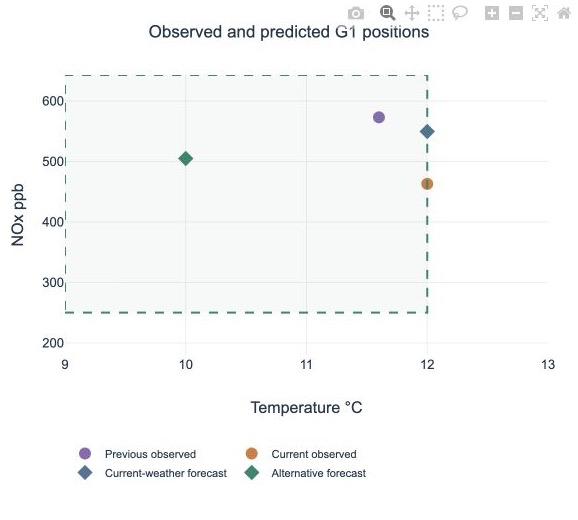

Figure 4. The 18:00 and 19:00 observations, current-weather prediction and cooler alternative share the recovered original G1 boundary.

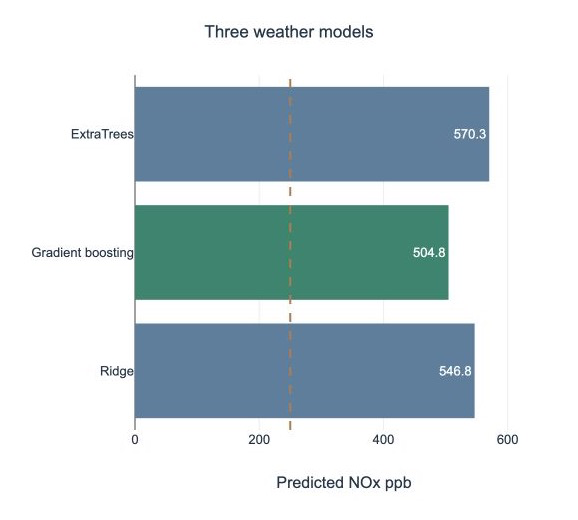

Figure 5. The three fixed weather-model families retain point-predicted membership at the primary 19:00 scenario.

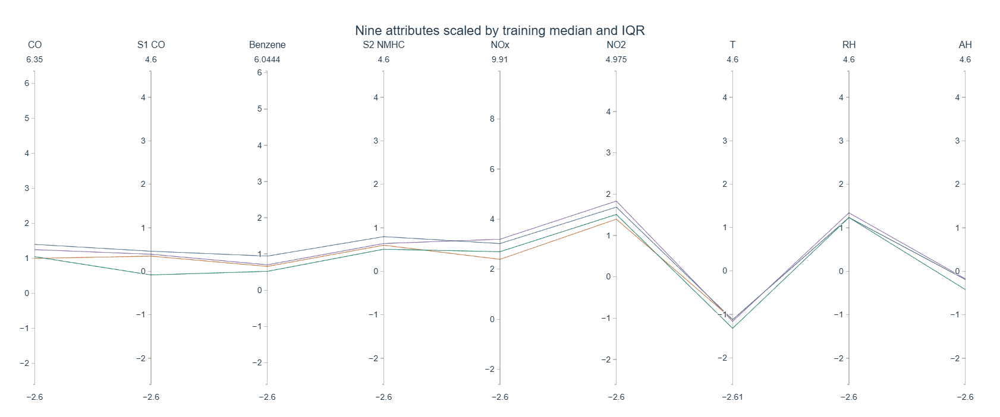

Figure 6. All nine attributes are compared using fixed training medians and IQRs. The alternative does not keep every response numerically unchanged.

We centre each attribute on its training median and scale it by its training interquartile range. This fixed reference allows comparison across different units. The four coloured lines show the previous and current observations, the current-weather prediction and the alternative-weather prediction, including changes in attributes beyond the two membership criteria.


The embedded image is the fixed four-profile scenario snapshot. In the webpage, selecting historical records switches to a single-purple record-inspection mode. Its legend and count update, while the separately labelled current-scenario table remains independent of that selection. Reset restores the four-profile comparison.


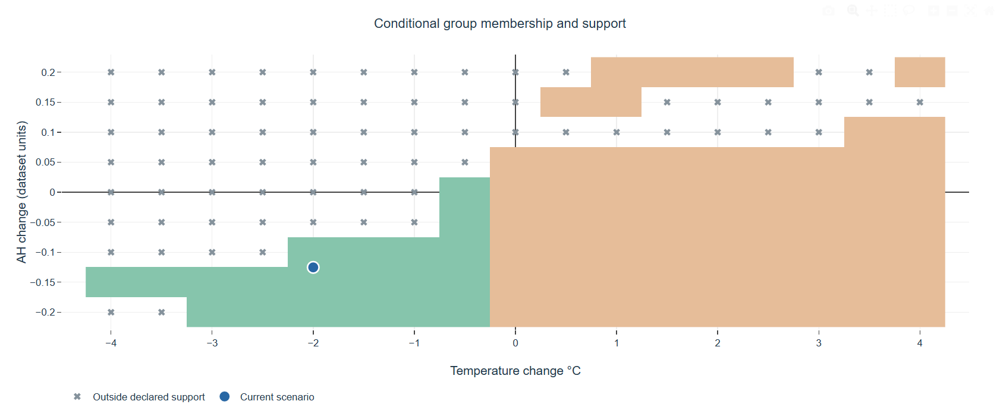

Figure 7. Full temperature and AH grid at 19:00. Green predicts G1 membership, orange predicts departure, and crosses fail declared support checks. The blue marker identifies the fixed-RH primary scenario.

The horizontal axis shows temperature change, and the vertical axis shows absolute-humidity change. Green cells predict G1 membership; orange cells predict departure. Crosses mark combinations that fail the declared support checks. On the interactive webpage, selecting a supported cell updates the projected position and nine-attribute comparison for that alternative. The embedded image shows a fixed snapshot.


### 3.5 Sensitivity and limitations

All 80 day-block gradient-boosting fits predict membership under the primary scenario. NOx estimates range from 458.62 to 578.05 ppb, with 5th and 95th percentiles of 465.55 and 562.46 ppb. These summaries describe the stability of fitted models; they are not success probabilities. We can bootstrap the NOx component independently because the model fits the six response estimators independently.

The historical high-NOx 95% error reference spans approximately 307.1 to 702.5 ppb, above the 250 ppb boundary. However, the nominal 90% reference covers only 78.4% of post-event observations. There are also **zero** earlier validation hours with both T < 12°C and predicted NOx > 250, leaving no validation evidence for calibration within the strict cool, high-NOx group. These checks cannot provide a probability of causal intervention success.

At 13:00, lagged NOx falls outside training support. At 02:00, the cooling alternative fails weather support, the models disagree, and only 42/80 bootstrap fits exceed 250 ppb. The nearby-boundary checks separately assess whether the observation remains an exit and whether its predicted point remains inside G1. They do not establish that the exact critical time is insensitive to the group definition.

The bootstrap summaries and the quoted 307.1 to 702.5 ppb range apply to the fixed 19:00 scenario: ΔT = −2°C, RH = 73.3%, T = 10.0°C and AH = 0.90115. They stay fixed when webpage controls change. The webpage separately labels the current Gradient boosting prediction and recalculates its historical-error references for the selected event and weather settings.


In [29]:
display(pd.read_csv(OUT/'bootstrap_summary.csv'))
display(pd.read_csv(OUT/'uncertainty.csv'))
display(pd.read_csv(OUT/'boundary_sensitivity.csv'))

,time,size,min,median,max,q05,q95,preserving_fits
0,2004-11-11 02:00:00,80,210.724123,251.168873,301.068497,219.232730,282.171218,42
1,2004-11-11 13:00:00,80,427.703989,546.693401,604.078299,485.297923,596.034230,80
2,2004-11-11 19:00:00,80,458.624197,514.611641,578.049935,465.552816,562.460919,80


,subset,n,quantile,absolute_error,lower,upper
0,all_validation,1500,0.90,99.625803,405.152100,604.403706
1,all_validation,1500,0.95,142.909885,361.868018,647.687788
2,forecast_NOx_above_250,423,0.90,166.484169,338.293734,671.262072
3,forecast_NOx_above_250,423,0.95,197.691199,307.086704,702.469102
4,cool_and_forecast_high,0,0.90,NaN,NaN,NaN
5,cool_and_forecast_high,0,0.95,NaN,NaN,NaN


,T_cut,NOx_cut,previous_member,observed_member,predicted_member
0,11.5,225.0,False,False,True
1,11.5,250.0,False,False,True
2,11.5,275.0,False,False,True
3,12.0,225.0,True,False,True
4,12.0,250.0,True,False,True
5,12.0,275.0,True,False,True
6,12.5,225.0,True,True,True
7,12.5,250.0,True,True,True
8,12.5,275.0,True,True,True


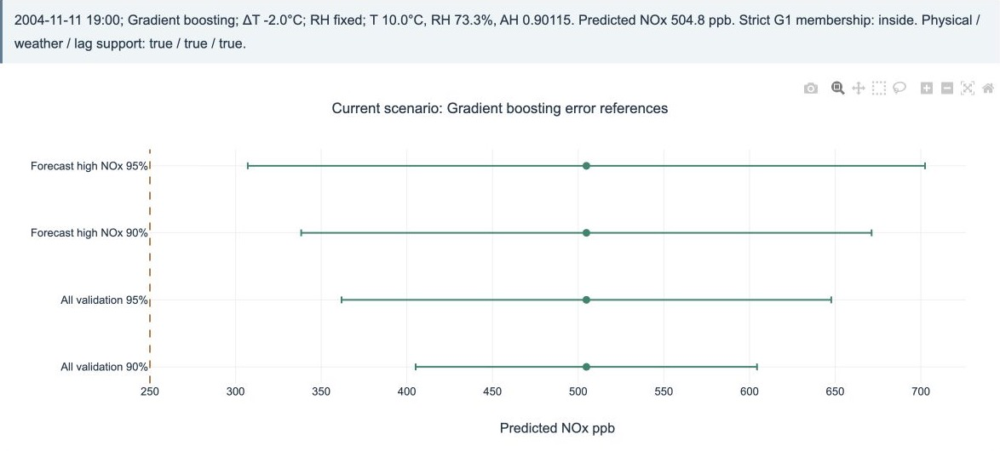

Figure 8. Historical error references for the selected gradient-boosting model. Lack of cold/high-NOx calibration hours and measured coverage limit interpretation.

Saved reference: 11 November, 19:00; Gradient boosting; ΔT = −2°C, RH fixed at 73.3%. The live webpage displays the current controls next to its updating error-reference chart and table.


### 3.6 Interactive webpage

Run the first resource-setup cell, then the next cell, and click the displayed HTTP link. The page provides the original evidence and recovered-member comparison, along with temperature and humidity controls, linked selection across nine attributes, a scenario grid and downloadable three-model predictions.

The accompanying `Task3_G1_Reverified.html` also opens directly in Chrome or Edge. GitHub's notebook preview displays saved content. To use the interactive page online, publish the supplied static webpage through GitHub Pages. A local 127.0.0.1 address is accessible only on the computer running the Python kernel.

The page separates historical-record inspection from scenario comparison. Uncertainty references update with the event and weather controls, while the fixed bootstrap summaries and primary conclusion have separate labels. Hovering over the validation plot shows observed and predicted NOx in ppb.


In [30]:
from notebook_web import show_dashboard_link
show_dashboard_link()

'http://127.0.0.1:50046/output/task3/stage5/task3_dashboard.html'

### 3.7 Findings and interpretation

| Item | Reverified evidence |
|---|---|
| Group continuity | The original time-grid selection is recovered as 966 timestamps, matching the strict rule with zero differences. |
| Critical moment | From 18:00 to 19:00 on 11 November, T/NOx changes from 11.6°C/573 ppb to 12.0°C/463 ppb. |
| Primary scenario | With temperature lowered by 2°C and RH held at 73.3%, all three weather models predict G1 membership and pass the support checks. |
| Selected prediction | Gradient boosting predicts NOx of 504.78 ppb at T = 10.0°C and AH = 0.90115. |
| Other attributes | All nine attributes are shown; preservation of the full profile is not claimed. |
| Original evidence limitation | Membership was digitised from B's raster image because the original lasso vertices are unavailable. |
| Prediction limitation | The scenario predicts one hour using factual histories, and temperature directly defines one group criterion. |
| Uncertainty limitation | There are no earlier strict cool/high calibration hours, and nominal historical-error coverage does not hold during the event period. |

The reanalysis provides a conditional scenario for the recovered Task 1 group, supporting point-predicted membership retention with the uncertainty described above. It does not establish causal pollution control, sustained weekly preservation or a fixed multivariate pollutant composition.


---
# 4. Task 4: Evaluation of the Visual Analytic Tool
**Owner: D (Tang Yaqing)** · evaluation design, verification and revision evidence



### Evaluation method and procedure


We evaluated whether the tool supports selecting and tracing the same hours across Task 1 views, comparing temporal changes in Task 2, and interpreting departures and alternative scenarios in Task 3. Task-based functional walkthroughs were combined with visual-design checks and the qualitative participant feedback described in Task 3.

These methods address different parts of this tool. Cross-view selection requires checking whether the same records remain highlighted after mouse release, rather than inspecting one screenshot. Monthly comparisons require consistent scales and readable attribute labels. Distinguishing historical observations, predictions and uncertainty references also requires checking how the explanations are understood.

Initial checks on 3 November 2026 identified 16 issues and two wording suggestions. View owners revised the notebook and dashboard, followed by fix verification on 4 November. Selections were observed for at least five seconds; filtering, empty states, reset, animation controls and scenario boundaries were checked. B's earlier Task 1 heuristic evaluation remains a separate contribution.

On 5 November, all 31 code cells were executed in order in an isolated Python 3.12.14 environment, after clearing old code outputs. Twelve Plotly outputs were generated. Twelve dashboard/evidence-link requests and all ten bundled evidence-consistency tests passed. Original defaults were retained: RUN_DASH=False and RECOMPUTE=False. This rerun regenerated data processing and Task 1/2 charts; Task 3 read the supplied results rather than retraining models or bootstrap fits.

| Analysis task | Operations checked | Evidence and judgment |
|---|---|---|
| Task 1: select and trace a pollution profile | Select records in the scatter/SPLOM, inspect linked views, filter seasons, clear and reset selections; brush or reorder parallel axes | Record counts and highlights agree; selections remain for at least five seconds; filters and empty states are explicit. Scatter/SPLOM box selection passed; in the latest package, parallel-axis brushing also updates the linked views (targeted retest on 5 November). |
| Task 2: compare monthly profiles | Play, pause and jump between months; switch NOx and temperature; inspect monthly curves, parallel coordinates and fingerprint values | Months remain paused; corresponding axes use comparable scales; names, units and IQR deviations are readable. July/November comparisons can be inspected without relying only on memory of animation. |
| Task 3: interpret a departure and alternative weather | Select historical records and reset; switch events/models and weather constraints; compare zero temperature change with the fixed-RH cooling scenario | Historical-record mode is distinguished from the four-profile scenario comparison. At 19:00, T=12°C remains outside strict G1 even when predicted NOx is high. Current error references and fixed bootstrap results are labelled separately. |

The following participant feedback complements these functional checks with qualitative evidence about understanding the interface.


### Results and limits


Across the recorded test rounds, all sixteen original issues passed within the tested settings. Two of them (parallel-axis linking and the count colour scale) passed only after a targeted retest of the latest package on 5 November. The issue register retains the original findings, owners and before/after evidence. These results describe issue verification, not participant success.

#### Reported participant feedback

The Task 3 evaluation involved Simon, a Computer Science student, and Xiangchen, a Media student, as described in that section. The available feedback supports the following summary.

| Participant | Task and difficulty described in Task 3 | Revision and reported follow-up |
|---|---|---|
| Simon — Computer Science | Adjusted temperature and humidity and examined the uncertainty panel; was unsure whether sliders also updated the bootstrap results for the fixed cooling scenario | Current-scenario error references were separated from fixed-scenario bootstrap results. After revisiting the revised interface, the explanations were reported as clearer. |
| Xiangchen — Media | Selected historical records in the scatterplot and inspected linked parallel coordinates; the legend did not clearly distinguish selected observations from scenario predictions | Selection labels and record count were revised, and the scenario table was separately labelled. After revisiting the revised interface, the information was reported as clearer. |

This qualitative feedback does not provide completion-time or success-rate measurements.

#### Functional verification results

| Check | Observed result |
|---|---|
| Scatter/SPLOM box selection | 1,164 scatter-selected records and 212 SPLOM-selected records persisted for at least five seconds with matching linked counts. |
| Season and variable empty states | No selected seasons produces an explicit prompt. One or zero SPLOM variables prompts selection of at least two variables. |
| Monthly comparisons | NOx and temperature panels share y-axis ranges across all 14 months; fingerprint Pause and month jumps work in the tested settings. |
| Fingerprint interpretation | Hover identifies month, hour, attribute and IQR deviation; the 13:00 NOx cell is approximately −0.30 IQR in July and +1.04 IQR in November. |
| Historical-record mode | Selecting 259 historical records updates the legend and count; reset restores the scenario comparison. An exactly-four-record selection is also labelled as historical records. |
| Strict group boundary | At 19:00 and ΔT=0°C, T=12°C and predicted NOx≈549.4 ppb are correctly shown outside strict G1. |
| Execution | Default full execution passed 31/31 code cells; 12 Plotly outputs, 12 HTTP checks and 10 bundled consistency tests passed. |

#### Remaining limitations

A targeted retest of the latest package on 5 November confirmed that parallel-axis brushing retained 2,861 records across the linked views for more than five seconds, and reset restored the full display. The count heatmap now uses a fixed 0–60 scale, with exact counts in hover text. A complete closed scatter lasso retained 363 records with matching cross-view counts. Monthly box-plot hover labels still include trace identifiers; this wording limitation is retained for submission. The latest package received targeted Task 1 interaction checks rather than another full run. Browser checks did not cover all viewport sizes, attribute combinations or weather scenarios.

The two-student feedback is small and qualitative. Functional corrections provide better conditions for reading visual evidence, but do not establish general gains in insight accuracy or speed. The default notebook rerun did not retrain Task 3 models, repeat 80 bootstrap fits or establish causal effects.


### Before and after evidence

**Scatterplot matrix labels — Task 1.** In the original three-variable matrix, names appeared inside neighbouring comparison panels. In the revised view, names sit in the corresponding diagonal cells. These images show a label-placement correction, not an increase in measured participant performance.

Before:

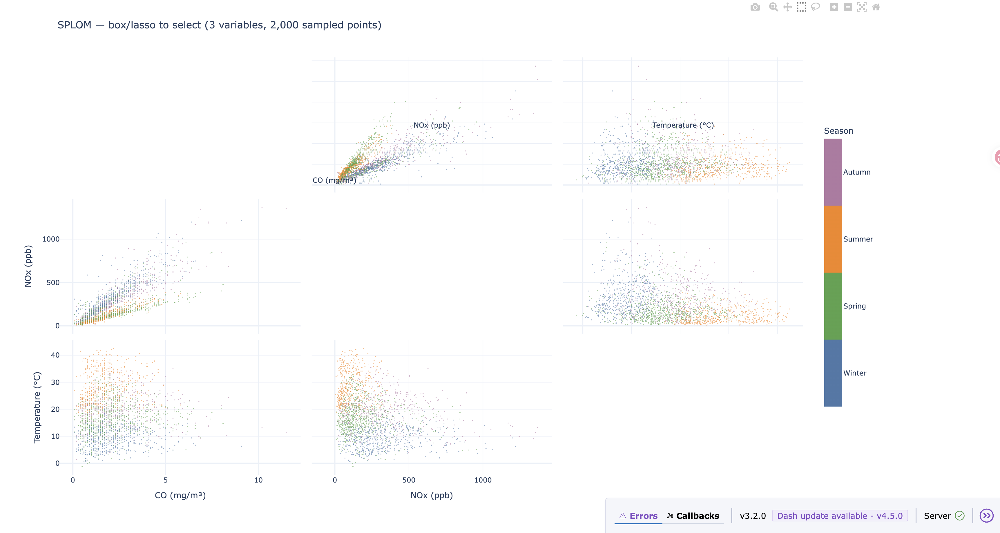

After:

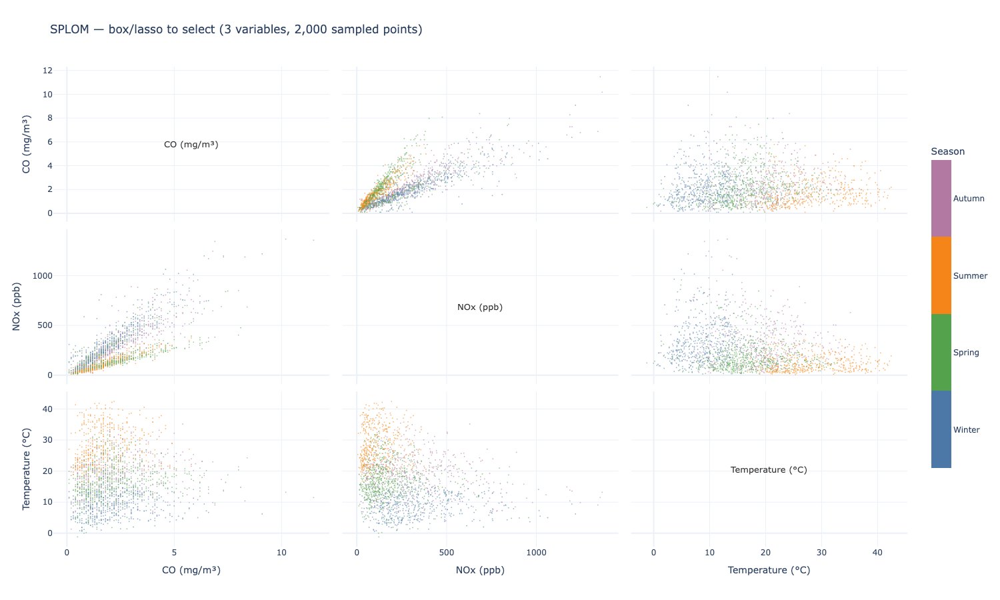

**Historical records and scenario comparison — Task 3.** The original historical selection retained the four-profile scenario explanation. In the revised view, the historical selection has its own mode label and record count; the scenario table is separately labelled. The screenshots contain different selected record sets and are compared for interface explanation, not for a change in the underlying observations.

Before:

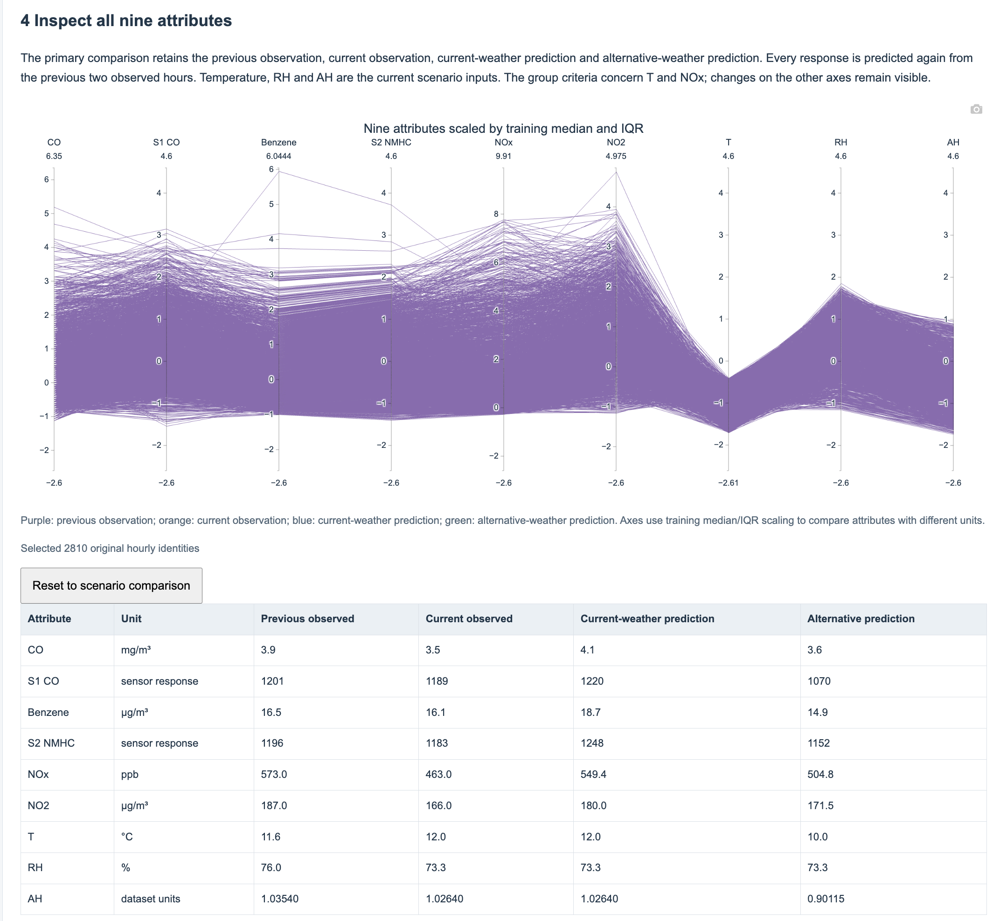

After:

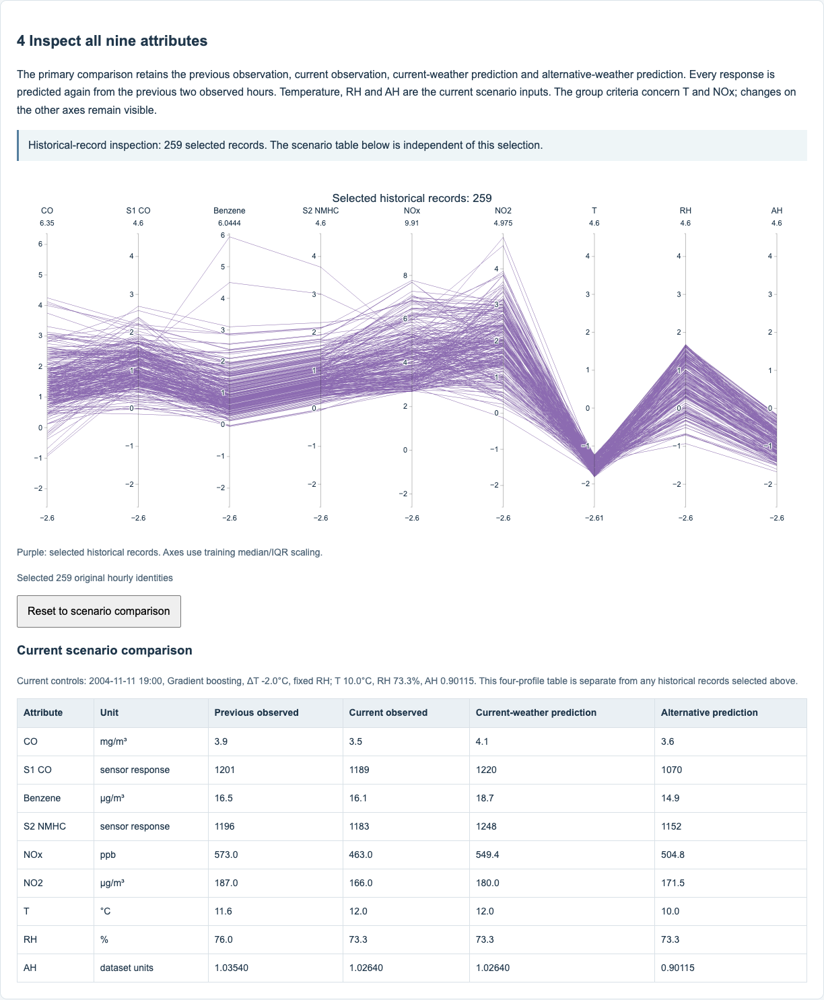


In [31]:
# Before/after evidence is embedded in the preceding Markdown cell.


### Design changes and contribution

| Finding | Design change | View / implementation owner | Improvement supported by the checks |
|---|---|---|---|
| Selected records disappeared or became inconsistent | Revised shared selection handling; scatter/SPLOM box selections now persist | Task 1 / B | The tested record sets can be followed across views for at least five seconds; parallel-axis brushing also propagates in the latest package. |
| SPLOM names appeared in neighbouring panels | Centred each variable name in its own diagonal cell; improved hover names and units | Task 1 / B | Variable-to-panel correspondence is clearer in the before/after evidence. |
| Empty controls produced misleading charts | Added explicit season and minimum-variable prompts | Task 1 / B | The display explains why no comparison can be shown. |
| Monthly curves used inconsistent scales | Applied shared y-axis ranges for each attribute | Task 2 / C | Heights can be compared across monthly panels for the tested NOx and temperature views. |
| Fingerprint controls and values were unclear | Added Pause, slider guidance and month/hour/attribute/IQR hover text | Task 2 / C | A month can be held and its standardised values interpreted directly. |
| Historical selections retained a scenario legend | Updated mode labels, count and independent scenario-table caption | Task 3 / A | Selected historical observations can be distinguished from four-profile scenario comparison. |
| Labels were clipped and observations/predictions ambiguous | Adjusted axis padding and value positions; clarified hover text | Task 3 / A | Tested event labels and model values can be read within the charts. |
| Fixed bootstrap results could be mistaken for current settings | Separated current-scenario error references from fixed cooling bootstrap summaries | Task 3 / A | Interpretation of the zero-change boundary and fixed scenario is explicit. |

**Contribution.** D designed the evaluation tasks, checked interactions and visual encodings across Tasks 1-3, prioritised issues and specified the expected behaviour. D maintained the bilingual issue/evidence register, verified revised versions, prepared the before/after comparisons, consolidated participant feedback, and documented the execution checks and limitations. D also prepared the Data/Task 4 text and coordinated report review. A, B and C implemented their respective view changes.

The figures and observed behaviours establish specific corrections; they do not quantify a universal usability improvement.


---
# 5. Submission checks

- [x] Data and Tasks 1–4 are documented in this notebook.
- [x] The shared numerical attributes and DateTime are retained; −200 values are missing and are not imputed; no clustering algorithm defines the groups.
- [x] The default notebook execution passed all 31 code cells on 5 November 2026; Task 3 uses supplied results rather than a fresh model fit.
- [x] Evaluation findings, implementation owners, remaining limitations and embedded before/after evidence are included.
- [x] Task 1 parallel-coordinates linking and the fixed 0–60 count colour scale passed the targeted 5 November retest; a closed scatter lasso also passed.
- [x] Confirm final report layout and cover fields. Figures 4–9 and 13 were re-laid out for readability in the shared report on 5 November; citation numbering and template formatting were checked.
- [x] Collect the individual reports and combine them with the group report into one PDF, observing the separate page limits. The cover does not count toward those limits.
- [ ] If a demonstration video is included, provide one .mov or .mp4 file of no more than three minutes.
